<p class="lead">Every project begins with the same unglamorous task: getting the data out of somebody else's system and into a table you can trust. This unit covers the four routes the laboratory uses — reading a file, calling a web interface, querying a relational database, and mapping identifiers between all of them — and treats each with the same question in mind: what exactly did I receive, and can I prove it later? We measure the file formats against each other instead of asserting their properties; we call a public API live, with the timeout, retry and caching discipline that a shared public service deserves; we build a small relational database from the course's frozen tables and answer the same question twice, once in pandas and once in SQL, and compare the two answers row by row.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad trata de cómo obtener los datos. Comparamos formatos midiéndolos: CSV, TSV, JSON, Parquet y HDF5, con sus tamaños y tiempos de lectura y escritura, y mostramos qué pierde un CSV (los tipos de dato). Presentamos los formatos del dominio — SMILES y SDF para moléculas, FASTA para secuencias, PDB y mmCIF para estructuras. Luego la web: anatomía de una petición HTTP, códigos de estado, paginación, límites de uso, reintentos con espera exponencial y almacenamiento en caché; <strong>esta es la única unidad del curso que hace llamadas reales a Internet</strong>, siempre dentro de <code>try/except</code> con 30 s de espera máxima y con el archivo congelado del curso como respaldo. Seguimos con los sistemas de identificadores (ChEMBL ID, PubChem CID, UniProt, PDB, GEO, InChIKey) y por qué el mapeo entre ellos es la fuente de error más frecuente de un proyecto integrativo. Terminamos con SQL en una hora sobre una base SQLite construida en el propio cuaderno, y respondemos la misma pregunta con pandas y con SQL para comparar ambos resultados.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Read and write the formats that circulate in the group — CSV/TSV, JSON, Parquet, HDF5 — and choose one for a given size and fidelity requirement, on measured evidence.</li>
<li>Recognise the domain formats you will meet (SMILES, SDF, FASTA, PDB/mmCIF) and state what each stores.</li>
<li>Query a public REST API with pagination, rate limiting, retries with exponential backoff and a disk cache, and always with a frozen fallback.</li>
<li>Name the identifier systems of the field (ChEMBL ID, PubChem CID, UniProt accession, PDB ID, GEO accession, InChIKey), and explain why mapping between them is error-prone.</li>
<li>Write SQL: SELECT, WHERE, ORDER BY, JOIN, GROUP BY, HAVING and subqueries; and say when a database beats a folder of CSV files.</li>
<li>Reproduce one answer in both pandas and SQL and verify that they agree.</li>
<li>Respect terms of use, licences and <code>robots.txt</code>, and recognise when scraping is not acceptable.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read it linearly with the code running. <strong>This is the only unit of the course whose notebook touches the network.</strong> Every live call is wrapped in <code>try/except</code> with a 30-second timeout and falls back to the frozen copy in <code>../data/</code>, and each such cell prints which path it took — so the notebook is deterministic for a reader without a connection, and honest about it. The packages used are the Unit 1 stack plus <code>requests</code>, <code>pyarrow</code> (for Parquet), <code>h5py</code> (for HDF5) and <code>rdkit</code> (for one identifier demonstration); all four are available in Colab, where only RDKit needs installing: run <code>!pip install rdkit h5py</code> once at the top. Temporary files are written to a scratch directory removed in the last cell.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit h5py
import sys, os, json, time, sqlite3, shutil, tempfile, platform, urllib.robotparser
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import h5py
import pyarrow

np.random.seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"

def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest

def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

SCRATCH = Path(tempfile.mkdtemp(prefix="u3_scratch_")).resolve()   # removed in the last cell
CACHE = SCRATCH / "api_cache"; CACHE.mkdir()
TIMEOUT = 30          # seconds; every network call in this notebook uses it
CHEMBL = "https://www.ebi.ac.uk/chembl/api/data"

raw = load_data("rock1_chembl_raw.csv")
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| pyarrow", pyarrow.__version__,
      "| h5py", h5py.__version__, "| requests", requests.__version__)
print("frozen ROCK1 activity table:", raw.shape, "(rows, columns)")
print("scratch directory:", SCRATCH.name)

python 3.11.15 | pandas 3.0.3 | pyarrow 25.0.0 | h5py 3.16.0 | requests 2.34.2
frozen ROCK1 activity table: (5089, 25) (rows, columns)
scratch directory: u3_scratch_s07geniq


## 1. The data landscape of the laboratory

Before any format or protocol, a map. A project in this group draws on five kinds of public resource, each with its own content, curation policy, release cycle and — most consequentially — its own identifiers.

- **ChEMBL** (EMBL-EBI) holds bioactivity measurements extracted and standardised from the medicinal-chemistry literature: compounds, targets, assays, documents and activities, with roughly twenty million activity records in recent releases<sup class="c"><a href="#r1">[1]</a></sup><sup class="c"><a href="#r2">[2]</a></sup><sup class="c"><a href="#r3">[3]</a></sup>. It is curated by humans, versioned by release, and licensed CC BY-SA. Its identifiers look like `CHEMBL3231` (a target) or `CHEMBL1201305` (a molecule), and its curation policy — what counts as the same assay, which values are flagged — is documented in detail<sup class="c"><a href="#r4">[4]</a></sup>.
- **PubChem** (NCBI) is larger and less curated: it aggregates depositor-submitted substances and computed compounds, with bioassay results attached<sup class="c"><a href="#r5">[5]</a></sup><sup class="c"><a href="#r6">[6]</a></sup>. Its identifiers are the **CID** (a compound) and **SID** (a deposited substance), and the distinction between them is a classic source of error.
- **BindingDB** curates binding affinities with an emphasis on measured $K_i$ and $K_d$ values, and cross-references ChEMBL and PubChem<sup class="c"><a href="#r7">[7]</a></sup>.
- **UniProt** is the reference for proteins: one accession (such as `Q13464` for human ROCK1) per sequence entry, with annotation, cross-references and isoform handling<sup class="c"><a href="#r8">[8]</a></sup>. **RCSB PDB** holds the experimental three-dimensional structures, named by a four-character code such as `2ESM`, and now also computed models<sup class="c"><a href="#r9">[9]</a></sup><sup class="c"><a href="#r10">[10]</a></sup>.
- **GEO** (NCBI) archives functional-genomics experiments: a series (`GSE16134`), its samples (`GSM…`) and the platform (`GPL570`) on which they were measured<sup class="c"><a href="#r11">[11]</a></sup><sup class="c"><a href="#r12">[12]</a></sup><sup class="c"><a href="#r13">[13]</a></sup>.

<div class="box bridge"><h4>Domain context — the file formats you will be handed</h4>
<p>Four formats carry the domain objects of this laboratory, and you will meet all four in your first month.</p>
<ul>
<li><strong>SMILES</strong> is a one-line text encoding of a molecular graph: <code>CC(=O)Oc1ccccc1C(=O)O</code> is aspirin. Atoms are element symbols, branches are parentheses, rings are opened and closed by matching digits, lower case means aromatic<sup class="c"><a href="#r14">[14]</a></sup>. It fits in a CSV column, which is why every table in this course stores structures as SMILES.</li>
<li><strong>SDF</strong> (structure-data file, from the MDL CTfile family<sup class="c"><a href="#r15">[15]</a></sup>) is the multi-record text format that chemistry software exchanges: per molecule, a counts line, one line per atom with 3-D coordinates, one line per bond, then arbitrary named data fields terminated by <code>$$$$</code>. Use it when coordinates or per-molecule annotations must travel with the structures.</li>
<li><strong>FASTA</strong> is the sequence format: a header line beginning with <code>&gt;</code> followed by the residue letters of a protein or nucleic acid<sup class="c"><a href="#r16">[16]</a></sup>. One file holds many sequences; nothing in it is typed, which is why sequence identifiers in FASTA headers are a recurring data-cleaning task.</li>
<li><strong>PDB</strong> and <strong>mmCIF</strong> hold macromolecular structures — atoms with coordinates, plus metadata about how they were determined. The legacy PDB format is a fixed-column text format whose 80-character lines cannot express large structures; mmCIF is the dictionary-based successor and is now the archival format<sup class="c"><a href="#r10">[10]</a></sup><sup class="c"><a href="#r17">[17]</a></sup>.</li>
</ul>
<p>This unit handles them as <em>formats</em> — how to recognise, read and write them. The chemistry and structural biology are the subject of the sister courses.</p></div>

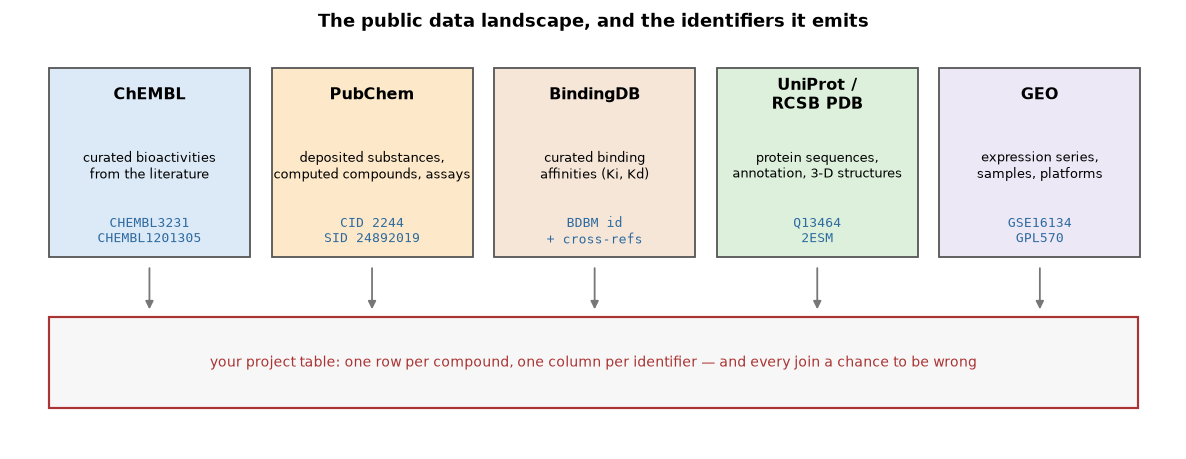

In [2]:
# Conceptual figure: what each resource holds, and the identifier that leaves it.
fig, ax = plt.subplots(figsize=(9.2, 3.6))
items = [("ChEMBL", "curated bioactivities\nfrom the literature", "CHEMBL3231\nCHEMBL1201305", "#dceaf7"),
         ("PubChem", "deposited substances,\ncomputed compounds, assays", "CID 2244\nSID 24892019", "#fde9c9"),
         ("BindingDB", "curated binding\naffinities (Ki, Kd)", "BDBM id\n+ cross-refs", "#f6e6d8"),
         ("UniProt /\nRCSB PDB", "protein sequences,\nannotation, 3-D structures", "Q13464\n2ESM", "#dcf0dc"),
         ("GEO", "expression series,\nsamples, platforms", "GSE16134\nGPL570", "#ece8f6")]
for i, (name, content, ids, colour) in enumerate(items):
    ax.add_patch(plt.Rectangle((i * 1.86, 0.55), 1.68, 1.25, facecolor=colour, edgecolor="#555555", lw=1.0))
    ax.text(i * 1.86 + 0.84, 1.62, name, ha="center", va="center", fontsize=8.6, fontweight="bold")
    ax.text(i * 1.86 + 0.84, 1.15, content, ha="center", va="center", fontsize=7.0)
    ax.text(i * 1.86 + 0.84, 0.72, ids, ha="center", va="center", fontsize=7.0,
            family="monospace", color="#2d6a9f")
    ax.annotate("", xy=(i * 1.86 + 0.84, 0.18), xytext=(i * 1.86 + 0.84, 0.5),
                arrowprops=dict(arrowstyle="-|>", color="#777777", lw=1.0))
ax.add_patch(plt.Rectangle((0.0, -0.45), 9.1, 0.6, facecolor="#f7f7f7", edgecolor="#a33", lw=1.2))
ax.text(4.55, -0.15, "your project table: one row per compound, one column per identifier — and every join a chance to be wrong",
        ha="center", va="center", fontsize=8.0, color="#a33")
ax.set_xlim(-0.3, 9.4); ax.set_ylim(-0.7, 2.0); ax.axis("off")
ax.set_title("The public data landscape, and the identifiers it emits")
fig.tight_layout()

<p class="caption"><b>Figure 1.</b> The five families of public resource this laboratory draws on, what each contains, and the identifiers it emits. Every arrow into the bottom box is an identifier mapping, and Section 5 shows why each one is a chance to be silently wrong. Note that the same molecule may appear as a ChEMBL id, a PubChem CID and a BindingDB entry — three names for one chemical object — while the same protein appears as a UniProt accession and several PDB codes, one per crystal structure.</p>

## 2. Formats, measured

Formats differ along four axes: **text or binary**, **with or without a schema** (does the file record the type of each column?), **row-oriented or column-oriented**, and **compressed or not**. Rather than assert the consequences, we measure them on the real 5,089-row ChEMBL table.

In [3]:
# Write the same table in five formats and measure size and write time.
numeric = raw.select_dtypes("number")

def write_hdf5(df, path):
    '''HDF5 stores arrays, not tables: one dataset per numeric column, gzip-compressed.'''
    with h5py.File(path, "w") as fh:
        for col in df.columns:
            fh.create_dataset(col, data=df[col].to_numpy(float), compression="gzip")

writers = {
    "CSV": lambda p: raw.to_csv(p, index=False),
    "TSV (gzip)": lambda p: raw.to_csv(p, sep="\t", index=False, compression="gzip"),
    "JSON (records)": lambda p: raw.to_json(p, orient="records"),
    "Parquet": lambda p: raw.to_parquet(p, index=False),
    "HDF5 (numeric only)": lambda p: write_hdf5(numeric, p),
}
ext = {"CSV": "csv", "TSV (gzip)": "tsv.gz", "JSON (records)": "json", "Parquet": "parquet",
       "HDF5 (numeric only)": "h5"}

rows = []
for name, writer in writers.items():
    path = SCRATCH / f"rock1.{ext[name]}"
    t0 = time.perf_counter(); writer(path); dt = time.perf_counter() - t0
    rows.append((name, path.stat().st_size / 1e6, dt,
                 "yes" if name in ("Parquet", "HDF5 (numeric only)") else "no",
                 "all 25" if name != "HDF5 (numeric only)" else f"{numeric.shape[1]} numeric"))
sizes = pd.DataFrame(rows, columns=["format", "MB", "write_s", "typed", "columns"])
print(sizes.round(3).to_string(index=False))
print("\nParquet is %.0f times smaller than CSV for the same 25 columns."
      % (sizes.loc[sizes['format'] == 'CSV', 'MB'].iloc[0] / sizes.loc[sizes['format'] == 'Parquet', 'MB'].iloc[0]))

             format    MB  write_s typed   columns
                CSV 4.586    0.066    no    all 25
         TSV (gzip) 0.186    0.085    no    all 25
     JSON (records) 6.945    0.030    no    all 25
            Parquet 0.248    0.066   yes    all 25
HDF5 (numeric only) 0.054    0.008   yes 6 numeric

Parquet is 19 times smaller than CSV for the same 25 columns.


<p class="caption"><b>Table (Section 2).</b> The same 5,089 × 25 table written five ways: file size, write time, whether the format records column types, and which columns it can hold. HDF5 appears with fewer columns on purpose — it stores arrays, not heterogeneous tables, so the text columns have no natural home in it.</p>

{'CSV': 29.8, 'TSV (gzip)': 31.9, 'JSON (records)': 38.0, 'Parquet': 2.7} ms


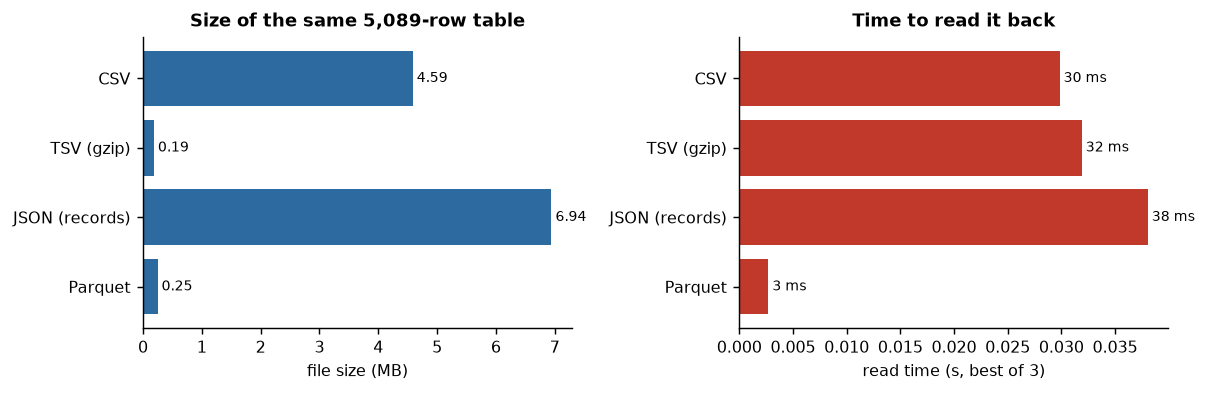

In [4]:
# Figure: size and read time per format, measured (best of three reads).
readers = {"CSV": lambda p: pd.read_csv(p), "TSV (gzip)": lambda p: pd.read_csv(p, sep="\t"),
           "JSON (records)": lambda p: pd.read_json(p, orient="records"),
           "Parquet": lambda p: pd.read_parquet(p)}
def best_of(func, repeats=3):
    '''Smallest wall-clock time of 'repeats' calls, in seconds.'''
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter()
        func()
        best = min(best, time.perf_counter() - t0)
    return best

read_times = {name: best_of(lambda r=reader, p=SCRATCH / f"rock1.{ext[name]}": r(p))
              for name, reader in readers.items()}

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.1))
names = list(readers)
axes[0].barh(names, [sizes.set_index("format").loc[n, "MB"] for n in names], color="#2d6a9f")
axes[0].set_xlabel("file size (MB)"); axes[0].set_title("Size of the same 5,089-row table")
for i, n in enumerate(names):
    axes[0].text(sizes.set_index("format").loc[n, "MB"], i, f" {sizes.set_index('format').loc[n, 'MB']:.2f}",
                 va="center", fontsize=8)
axes[1].barh(names, [read_times[n] for n in names], color="#c0392b")
axes[1].set_xlabel("read time (s, best of 3)"); axes[1].set_title("Time to read it back")
for i, n in enumerate(names):
    axes[1].text(read_times[n], i, f" {read_times[n]*1000:.0f} ms", va="center", fontsize=8)
for a in axes:
    a.invert_yaxis()
fig.tight_layout()
print({k: round(v * 1000, 1) for k, v in read_times.items()}, "ms")

<p class="caption"><b>Figure 2.</b> File size (left) and read time (right) for the same table in four readable formats, measured on the machine that built this page. Parquet is both the smallest and among the fastest, because it stores each column separately in a typed, compressed, binary layout; JSON is the largest because it repeats every column name in every record; gzipped TSV is small but pays decompression on every read. CSV is in the middle on both axes, and wins only on universality. The numbers printed under the figure are the measured read times in milliseconds.</p>

The recommendation that follows from the measurement, and that this group applies: **CSV for anything a human or a stranger's tool must read** (raw downloads, small result tables, supplementary material), **Parquet for intermediate tables inside a pipeline**, **HDF5 or `.npz` for large numeric arrays** such as trajectories and fingerprint matrices<sup class="c"><a href="#r18">[18]</a></sup><sup class="c"><a href="#r19">[19]</a></sup>, and **JSON for nested metadata** — a manifest, an API response — where the structure is a tree rather than a rectangle<sup class="c"><a href="#r20">[20]</a></sup>.

### 2.1 What a CSV loses

A CSV file stores characters. The *types* — this column is an integer, that one is a date, this identifier must keep its leading zero — exist only in the reader's guess. The next cell exhibits the failure on constructed data of exactly the kinds that occur in this field.

In [5]:
# The CSV type-loss experiment: four columns that do not survive a round trip.
original = pd.DataFrame({
    "plate_well": ["0012", "0345", "1000"],          # an identifier with meaningful leading zeros
    "n_replicates": pd.array([3, None, 5], dtype="Int64"),  # a nullable integer
    "measured_on": pd.to_datetime(["2026-01-15", "2026-02-02", "2026-03-30"]),
    "is_active": [True, False, True],
    "comment": ["ok", "NA", "n.d."],                 # literal text that looks like missingness
})
original.to_csv(SCRATCH / "types.csv", index=False)
roundtrip = pd.read_csv(SCRATCH / "types.csv")

print("dtypes before -> after:")
for col in original.columns:
    print(f"  {col:<14} {str(original[col].dtype):<16} -> {roundtrip[col].dtype}")
print("\nvalues that changed meaning:")
print("  plate_well  :", original['plate_well'].tolist(), "->", roundtrip['plate_well'].tolist())
print("  n_replicates:", original['n_replicates'].tolist(), "->", roundtrip['n_replicates'].tolist())
print("  comment     :", original['comment'].tolist(), "->", roundtrip['comment'].tolist())

# Parquet keeps the schema: the round trip is exact.
original.to_parquet(SCRATCH / "types.parquet", index=False)
pq = pd.read_parquet(SCRATCH / "types.parquet")
print("\nParquet round trip preserves every dtype:",
      all(str(original[c].dtype) == str(pq[c].dtype) for c in original.columns))
print("and every value:", original.equals(pq))

dtypes before -> after:
  plate_well     str              -> int64
  n_replicates   Int64            -> float64
  measured_on    datetime64[us]   -> str
  is_active      bool             -> bool
  comment        str              -> str

values that changed meaning:
  plate_well  : ['0012', '0345', '1000'] -> [12, 345, 1000]
  n_replicates: [3, <NA>, 5] -> [3.0, nan, 5.0]
  comment     : ['ok', 'NA', 'n.d.'] -> ['ok', nan, 'n.d.']

Parquet round trip preserves every dtype: True
and every value: True


Four distinct losses, each of which has corrupted a real dataset. The identifier `0012` came back as the integer 12, so a join against the plate map now fails for every well below 1000. The nullable integer column became floating point, because `NaN` is not an integer — so `n_replicates` is now `3.0`, and a later `groupby` on it produces float keys. The timestamp came back as text. And the literal comment `"NA"` was read as *missing*, silently converting a curator's note into an absence. The Parquet round trip, by contrast, is exact in both dtypes and values, because the format carries a schema.

<div class="box warn"><h4>The three defences when you must use CSV</h4>
<p>Pass explicit types: <code>pd.read_csv(path, dtype={"plate_well": "string", "n_replicates": "Int64"})</code>. Pass <code>parse_dates=["measured_on"]</code> for dates. And pass <code>keep_default_na=False, na_values=[""]</code> when a column may legitimately contain the strings <code>NA</code>, <code>None</code> or <code>null</code> as data. A reader without these arguments is a guess, and the guess changes between pandas versions.</p></div>

In [6]:
# Column pruning: the practical advantage of a columnar format on a wide table.
wide = pd.concat([raw] * 20, ignore_index=True)          # 101,780 rows x 25 columns
wide.to_parquet(SCRATCH / "wide.parquet", index=False)
wide.to_csv(SCRATCH / "wide.csv", index=False)
print("wide table:", wide.shape, "| parquet %.1f MB | csv %.1f MB"
      % ((SCRATCH / 'wide.parquet').stat().st_size / 1e6, (SCRATCH / 'wide.csv').stat().st_size / 1e6))

two_cols = ["molecule_chembl_id", "standard_value"]
timings = {}
t0 = time.perf_counter(); pd.read_parquet(SCRATCH / "wide.parquet"); timings["parquet, all 25 columns"] = time.perf_counter() - t0
t0 = time.perf_counter(); pd.read_parquet(SCRATCH / "wide.parquet", columns=two_cols); timings["parquet, 2 columns"] = time.perf_counter() - t0
t0 = time.perf_counter(); pd.read_csv(SCRATCH / "wide.csv"); timings["csv, all 25 columns"] = time.perf_counter() - t0
t0 = time.perf_counter(); pd.read_csv(SCRATCH / "wide.csv", usecols=two_cols); timings["csv, 2 columns"] = time.perf_counter() - t0
for k, v in timings.items():
    print(f"  {k:<26} {v*1000:7.0f} ms")
print("\nreading 2 of 25 columns is %.1f times faster in Parquet, but only %.1f times faster in CSV"
      % (timings['parquet, all 25 columns'] / timings['parquet, 2 columns'],
         timings['csv, all 25 columns'] / timings['csv, 2 columns']))

wide table: (101780, 25) | parquet 0.9 MB | csv 91.7 MB
  parquet, all 25 columns         53 ms
  parquet, 2 columns               3 ms
  csv, all 25 columns            505 ms
  csv, 2 columns                 251 ms

reading 2 of 25 columns is 20.8 times faster in Parquet, but only 2.0 times faster in CSV


The asymmetry in that output is the definition of a columnar format. Parquet stores each column as a separate compressed block, so asking for two of twenty-five columns reads two blocks and skips the rest. A CSV reader must parse every character of every line to find the commas, so restricting the columns saves only the construction of the unwanted columns, not the parsing. On a table of a hundred thousand rows the difference is already visible; on the ten-million-row output of a virtual-screening campaign (Unit 19) it is the difference between an interactive analysis and a coffee break.

<div class="exercise"><h4>Exercise 1</h4>
<p>Write <code>wide</code> to Parquet twice, once with <code>compression="snappy"</code> (the default) and once with <code>compression="gzip"</code>, and compare file size against write and read time. Then convert the three low-cardinality text columns to <code>category</code> before writing and repeat: by how much does the Parquet file shrink, and why does the dictionary encoding of a categorical column help a columnar format so much more than it helps a CSV?</p></div>

  rows  csv_MB  parquet_MB  ratio
  5089    4.59        0.25   18.5
 10178    9.17        0.28   32.3
 25445   22.93        0.40   56.9
 50890   45.85        0.58   78.8
101780   91.71        0.93   98.2


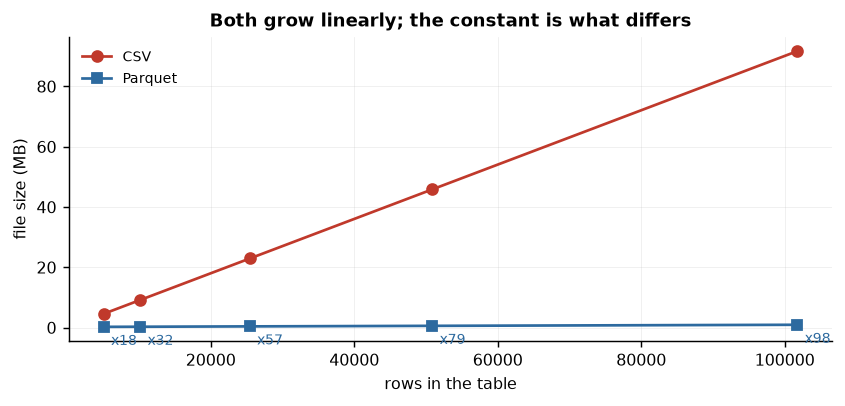

In [7]:
# How the choice scales: size of each format as the table grows.
scaling = []
for factor in [1, 2, 5, 10, 20]:
    big = pd.concat([raw] * factor, ignore_index=True)
    p_csv, p_pq = SCRATCH / f"s{factor}.csv", SCRATCH / f"s{factor}.parquet"
    big.to_csv(p_csv, index=False); big.to_parquet(p_pq, index=False)
    scaling.append((len(big), p_csv.stat().st_size / 1e6, p_pq.stat().st_size / 1e6))
    p_csv.unlink(); p_pq.unlink()
scal = pd.DataFrame(scaling, columns=["rows", "csv_MB", "parquet_MB"])
scal["ratio"] = (scal["csv_MB"] / scal["parquet_MB"]).round(1)
print(scal.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.6, 3.2))
ax.plot(scal["rows"], scal["csv_MB"], "o-", color="#c0392b", label="CSV")
ax.plot(scal["rows"], scal["parquet_MB"], "s-", color="#2d6a9f", label="Parquet")
for r, c, p, ratio in scal.itertuples(index=False):
    ax.annotate(f"x{ratio:.0f}", (r, p), textcoords="offset points", xytext=(4, -10), fontsize=7.5, color="#2d6a9f")
ax.set_xlabel("rows in the table"); ax.set_ylabel("file size (MB)")
ax.set_title("Both grow linearly; the constant is what differs")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25, lw=0.4)
fig.tight_layout()

<p class="caption"><b>Figure 3.</b> File size against row count for CSV and Parquet, from the 5,089-row table up to twenty copies of it. Both are linear — no format changes the asymptotic behaviour — but the ratio annotated at each point is roughly constant and large, because the repeated SMILES strings and assay descriptions compress and dictionary-encode extremely well in a columnar layout. When someone asks "will this scale?", this is the shape of answer to give: the same complexity class, a different constant, and the constant is what you will feel.</p>

## 3. The domain formats in practice

The formats of Section 2 hold tables. The four domain formats hold objects: molecules, sequences, structures. The next cell writes a small example of each, in the correct syntax, and parses it back — so that the first time you are handed one of these files, nothing about it is unfamiliar.

In [8]:
# Write and parse one small example of each domain format.
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.inchi import MolToInchiKey
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.*")        # silence RDKit parse chatter in a teaching notebook

# (a) SMILES: three real ROCK1-relevant molecules, straight out of the frozen table.
smiles_sample = raw.loc[raw["canonical_smiles"].notna(), "canonical_smiles"].head(3).tolist()
mols = [Chem.MolFromSmiles(s) for s in smiles_sample]
print("(a) SMILES parsed:", [m.GetNumAtoms() for m in mols], "heavy atoms each")

# (b) SDF: the same molecules with 3-D coordinates and a data field, written and read back.
sdf_path = SCRATCH / "sample.sdf"
writer = Chem.SDWriter(str(sdf_path))
for i, m in enumerate(mols):
    m3d = Chem.AddHs(m)
    AllChem.EmbedMolecule(m3d, randomSeed=0)        # deterministic conformer
    m3d.SetProp("_Name", f"compound_{i+1}")
    m3d.SetProp("pActivity", f"{7.0 + i * 0.3:.2f}")
    writer.write(m3d)
writer.close()
back = [m for m in Chem.SDMolSupplier(str(sdf_path), removeHs=False) if m is not None]
print("(b) SDF  : wrote", len(mols), "records,", sdf_path.stat().st_size, "bytes; read back",
      len(back), "with fields", list(back[0].GetPropNames()))
print("    first 4 lines of the file:", [l for l in sdf_path.read_text().splitlines()[:4]])

# (c) FASTA: a fragment of the ROCK1 kinase-domain sequence, parsed without a library.
fasta = (">sp|Q13464|ROCK1_HUMAN Rho-associated protein kinase 1 OS=Homo sapiens\n"
         "MSTGDSFETRFEKMDNLLRDPKSEVNSDCLLDGLDALVYDLDFPALRKNKNIDNFLSRYK\n"
         "DTINKIRDLRMKAEDYEVVKVIGRGAFGEVQLVRHKSTRKVYAMKLLSKFEMIKRSDSAF\n")
(SCRATCH / "rock1.fasta").write_text(fasta, encoding="utf-8")
records, header, seq = {}, None, []
for line in (SCRATCH / "rock1.fasta").read_text().splitlines():
    if line.startswith(">"):
        if header: records[header] = "".join(seq)
        header, seq = line[1:], []
    else:
        seq.append(line.strip())
records[header] = "".join(seq)
acc = list(records)[0].split("|")[1]
print(f"(c) FASTA: 1 record, accession {acc}, {len(records[list(records)[0]])} residues parsed")

# (d) PDB: three ATOM records in fixed-column format, parsed by column position.
pdb_lines = ["ATOM      1  N   MET A   1      27.340  24.430   2.614  1.00  9.67           N",
             "ATOM      2  CA  MET A   1      26.266  25.413   2.842  1.00 10.38           C",
             "ATOM      3  C   MET A   1      26.913  26.639   3.531  1.00  9.62           C"]
(SCRATCH / "fragment.pdb").write_text("\n".join(pdb_lines) + "\nEND\n", encoding="utf-8")
atoms = [{"serial": int(l[6:11]), "name": l[12:16].strip(), "resname": l[17:20].strip(),
          "chain": l[21], "resseq": int(l[22:26]),
          "xyz": (float(l[30:38]), float(l[38:46]), float(l[46:54])), "bfactor": float(l[60:66])}
         for l in pdb_lines]
print("(d) PDB  :", pd.DataFrame(atoms)[["serial", "name", "resname", "chain", "xyz", "bfactor"]]
      .to_string(index=False))

(a) SMILES parsed: [17, 25, 16] heavy atoms each
(b) SDF  : wrote 3 records, 8873 bytes; read back 3 with fields ['pActivity']
    first 4 lines of the file: ['compound_1', '     RDKit          3D', '', ' 27 29  0  0  0  0  0  0  0  0999 V2000']
(c) FASTA: 1 record, accession Q13464, 120 residues parsed
(d) PDB  :  serial name resname chain                     xyz  bfactor
      1    N     MET     A   (27.34, 24.43, 2.614)     9.67
      2   CA     MET     A (26.266, 25.413, 2.842)    10.38
      3    C     MET     A (26.913, 26.639, 3.531)     9.62


Four formats, four parsing strategies, and the strategies are the lesson. SMILES is a *string* and needs a chemistry toolkit to interpret. SDF is a *record-oriented text format* with a terminator, so libraries supply a supplier/iterator; note that the data fields travelled with the molecules and came back intact. FASTA needs no library at all — the fifteen-line parser above is the whole format, which is why everyone writes one and why header conventions (`sp|Q13464|ROCK1_HUMAN`) are the only hard part. PDB is a **fixed-column** format: the x-coordinate is characters 31–38 of the line, not "the sixth field", so splitting on whitespace is wrong and breaks the moment a field touches its neighbour. That fragility is exactly why mmCIF replaced it as the archival format<sup class="c"><a href="#r10">[10]</a></sup><sup class="c"><a href="#r17">[17]</a></sup>.

## 4. Web APIs: asking a server politely

A **REST API** exposes resources at URLs and returns representations of them, usually JSON<sup class="c"><a href="#r21">[21]</a></sup><sup class="c"><a href="#r20">[20]</a></sup>. ChEMBL's interface is documented as a research tool in its own right<sup class="c"><a href="#r32">[32]</a></sup>, and its deposition pipeline explains why the same assay can appear with different provenance in successive releases<sup class="c"><a href="#r33">[33]</a></sup>. The anatomy of a request is: a method (`GET` to read), a base URL, a path naming the resource, a query string of parameters, and headers. The response carries a status code — `200` success, `3xx` redirect, `400` your request was malformed, `404` no such resource, `429` you are being rate-limited, `5xx` the server failed — plus the body.

Four disciplines separate a well-behaved client from a nuisance, and public services such as the EBI and NCBI depend on users observing them.

1. **Timeouts.** Every call passes an explicit timeout; without one, a stalled connection hangs your notebook forever. In this notebook it is 30 seconds.
2. **Pagination.** Large result sets are returned in pages. ChEMBL's API reports a `page_meta` block with the total count and the URL of the next page; you loop until there is no next page, and you cap the loop.
3. **Retries with exponential backoff.** A transient `5xx` or `429` should be retried after a wait that doubles each time (1 s, 2 s, 4 s, …), with a small random jitter so that many clients do not retry in lockstep. A `404` should never be retried — the resource is simply not there.
4. **Caching.** A response that will not change should be written to disk and re-used. This is politeness and speed at once: the second run of your analysis should not touch the network at all.

retry on: [429, 500, 502, 503, 504] | never retry: 400, 401, 403, 404 (the request itself is wrong)
cumulative wait if all six attempts fail: 63 s


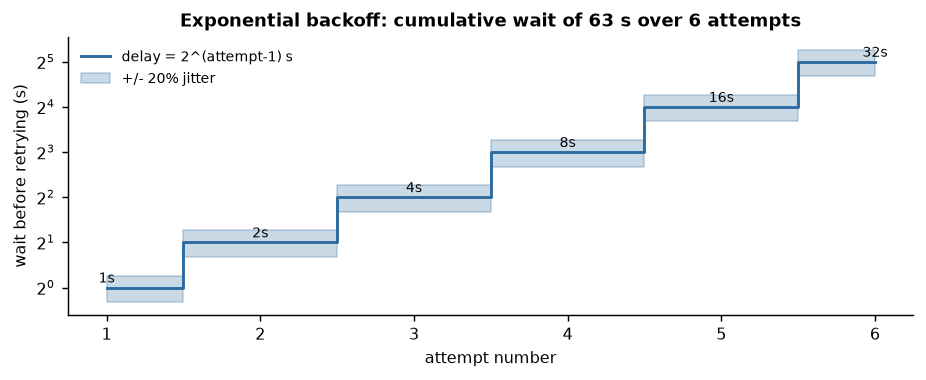

In [9]:
# The backoff schedule, and the decision rule for which statuses deserve a retry (conceptual figure).
RETRY_ON = {429, 500, 502, 503, 504}
attempts = np.arange(1, 7)
delays = 2.0 ** (attempts - 1)
jitter_low, jitter_high = delays * 0.8, delays * 1.2

fig, ax = plt.subplots(figsize=(7.2, 3.0))
ax.step(attempts, delays, where="mid", color="#2d6a9f", lw=1.6, label="delay = 2^(attempt-1) s")
ax.fill_between(attempts, jitter_low, jitter_high, step="mid", alpha=0.25, color="#2d6a9f",
                label="+/- 20% jitter")
for a_, d in zip(attempts, delays):
    ax.text(a_, d * 1.08, f"{d:.0f}s", ha="center", fontsize=7.5)
ax.set_yscale("log", base=2); ax.set_xlabel("attempt number"); ax.set_ylabel("wait before retrying (s)")
ax.set_title("Exponential backoff: cumulative wait of %.0f s over 6 attempts" % delays.sum())
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
print("retry on:", sorted(RETRY_ON), "| never retry: 400, 401, 403, 404 (the request itself is wrong)")
print("cumulative wait if all six attempts fail: %.0f s" % delays.sum())

<p class="caption"><b>Figure 4.</b> The exponential-backoff schedule used by the client below, on a logarithmic axis, with the jitter band that prevents synchronised retries across many clients. Six attempts span a cumulative wait of about a minute — enough to ride out a brief server hiccup, short enough not to hide a real outage. The printed line states the rule that matters as much as the schedule: statuses that mean "your request is wrong" are never retried, because retrying them is pure load on a shared service.</p>

In [10]:
# A polite client: timeout, retries with backoff and jitter, and a disk cache.
def api_get(url, params=None, attempts=4, timeout=TIMEOUT, cache=CACHE):
    '''GET with retries, backoff and caching. Returns (payload, provenance) and never raises.'''
    key = str(abs(hash((url, json.dumps(params or {}, sort_keys=True))))) + ".json"
    cached = Path(cache) / key
    if cached.exists():
        return json.loads(cached.read_text(encoding="utf-8")), "cache"
    last = ""
    for attempt in range(1, attempts + 1):
        try:
            resp = requests.get(url, params=params, timeout=timeout,
                                headers={"Accept": "application/json"})
            if resp.status_code == 200:
                payload = resp.json()
                cached.write_text(json.dumps(payload), encoding="utf-8")
                return payload, f"network (attempt {attempt})"
            if resp.status_code not in RETRY_ON:
                return None, f"HTTP {resp.status_code} (not retried)"
            last = f"HTTP {resp.status_code}"
        except Exception as exc:                      # the one justified broad catch: any failure must fall back
            last = f"{type(exc).__name__}: {str(exc)[:60]}"
        if attempt < attempts:
            time.sleep(min(2.0 ** (attempt - 1), 4.0))
    return None, f"gave up after {attempts} attempts ({last})"

payload, provenance = api_get(f"{CHEMBL}/activity.json",
                              params={"target_chembl_id": "CHEMBL3231", "standard_type": "IC50", "limit": 5})
print("provenance:", provenance)
if payload is not None:
    print("top-level keys :", list(payload))
    print("page_meta      :", {k: payload['page_meta'][k] for k in ['limit', 'offset', 'total_count']})
    first = payload["activities"][0]
    print("fields per record:", len(first))
    for field in ["activity_id", "molecule_chembl_id", "standard_type", "standard_relation",
                  "standard_value", "standard_units", "assay_chembl_id"]:
        print(f"   {field:<22} {first.get(field)}")
else:
    print("no live response; every number below comes from the frozen snapshot in ../data/")

provenance: network (attempt 1)
top-level keys : ['activities', 'page_meta']
page_meta      : {'limit': 5, 'offset': 0, 'total_count': 3262}
fields per record: 47
   activity_id            1475830
   molecule_chembl_id     CHEMBL189657
   standard_type          IC50
   standard_relation      =
   standard_value         13.0
   standard_units         nM
   assay_chembl_id        CHEMBL828501


The cell printed its own provenance — `network`, `cache`, or a failure with its reason — which is the habit to copy: **a function that may or may not have reached the internet must say which happened**. If the build machine had no connection, the message says so and the notebook continues on the frozen file, with every subsequent number still reproducible.

### 4.1 Pagination, and checking the live service against the frozen snapshot

The same query asked without a `limit` returns thousands of records in pages. The next cell walks at most three pages, counts what the service reports, and compares that count with the frozen table shipped with this course — the single most informative check you can run on a downloaded dataset, because it tells you whether the database has moved since the snapshot was taken.

In [11]:
# Pagination, capped, with the frozen snapshot as both fallback and reference.
frozen_ic50 = int((raw["standard_type"] == "IC50").sum())
collected, pages, total_reported = [], 0, None
url, params = f"{CHEMBL}/activity.json", {"target_chembl_id": "CHEMBL3231",
                                          "standard_type": "IC50", "limit": 1000}
while pages < 3:
    page, prov = api_get(url, params=params)
    if page is None:
        print(f"page {pages + 1}: unavailable ({prov}) - stopping and using the frozen file")
        break
    pages += 1
    collected.extend(page["activities"])
    total_reported = page["page_meta"]["total_count"]
    print(f"page {pages}: {len(page['activities']):>4} records  ({prov}); total reported by the service: {total_reported}")
    nxt = page["page_meta"].get("next")
    if not nxt:
        break
    url, params = "https://www.ebi.ac.uk" + nxt, None

print("\nrecords collected in this session :", len(collected))
print("IC50 records in the frozen snapshot:", frozen_ic50)
if total_reported is not None:
    print("live total vs frozen snapshot      :", total_reported, "vs", frozen_ic50,
          "->", "unchanged" if total_reported == frozen_ic50 else
          f"the database has moved by {total_reported - frozen_ic50:+d} records since the snapshot")
else:
    print("no live total available; the frozen snapshot is the reference for this notebook")

page 1: 1000 records  (network (attempt 1)); total reported by the service: 3262
page 2: 1000 records  (network (attempt 1)); total reported by the service: 3262
page 3: 1000 records  (network (attempt 1)); total reported by the service: 3262

records collected in this session : 3000
IC50 records in the frozen snapshot: 3262
live total vs frozen snapshot      : 3262 vs 3262 -> unchanged


Read whichever message the cell printed. If the live total equals the frozen count, the snapshot is still current and anything you compute from either source agrees. If it differs, you have just measured the phenomenon Unit 2 warned about — a moving database — and you now know by how much. If the network was unavailable, the frozen file is the reference and the notebook is unaffected. In all three cases the analysis that follows is reproducible, because it reads `../data/`, and the live call served only to *date* the snapshot.

<div class="box warn"><h4>Terms of use are part of the method</h4>
<p>Public APIs are shared infrastructure. Identify your client, respect published rate limits, cache aggressively, never parallelise a crawl across dozens of connections, and prefer the bulk download when you need more than a few thousand records — EBI and NCBI both publish full dumps precisely so that nobody has to page through millions of records. For production-scale work use the official clients (<code>chembl_webresource_client</code>, NCBI E-utilities, the UniProt and RCSB search APIs) rather than hand-rolled loops, and for the whole of ChEMBL use the official SQLite or PostgreSQL dump, which is one download and then local SQL. This notebook deliberately does not download the dump — it is several gigabytes — but Section 6 shows the SQL you would write against it.</p></div>

## 5. Identifiers, and why mapping is the first thing that breaks

Each resource names its objects in its own way: `CHEMBL1201305`, PubChem `CID 2244`, UniProt `Q13464`, PDB `2ESM`, GEO `GSE16134`. Integrating two resources means mapping between two naming systems, and that mapping is the most error-prone step in a project, for four structural reasons.

- **Different granularity.** A PubChem SID is a *deposited substance* (one depositor's record, possibly a mixture or a salt); a CID is a *standardised compound*. A UniProt accession names a sequence entry; a PDB code names one experimental structure of (part of) it, and one protein may have dozens.
- **Many-to-one and one-to-many.** Several ChEMBL molecule ids collapse onto one standardised structure when salts and charge states are normalised; one UniProt accession maps to many PDB codes; one gene symbol maps to several probe sets on a microarray platform.
- **Structure-based identifiers are not free of pitfalls.** The **InChIKey** is a 27-character hash of the standard InChI: a 14-character skeleton block, a 10-character block for stereochemistry and isotopes, and a final character for the protonation state<sup class="c"><a href="#r22">[22]</a></sup>. Two stereoisomers therefore share the first block and differ in the second — which is a feature when you want "the same skeleton" and a bug when you match on the first block and silently merge enantiomers.
- **Identifiers are retired and merged.** Databases deprecate entries, and a mapping table downloaded last year may point at accessions that no longer exist. UniChem exists precisely to track cross-references between chemical structure identifiers across resources<sup class="c"><a href="#r23">[23]</a></sup>, and the error rates of public chemistry databases — wrong structures attached to right identifiers and vice versa — have been quantified repeatedly<sup class="c"><a href="#r31">[31]</a></sup>.

In [12]:
# InChIKey anatomy, and the stereochemistry trap, computed with RDKit.
pairs = {"aspirin": "CC(=O)Oc1ccccc1C(=O)O",
         "(S)-ibuprofen": "C[C@@H](c1ccc(CC(C)C)cc1)C(=O)O",
         "(R)-ibuprofen": "C[C@H](c1ccc(CC(C)C)cc1)C(=O)O",
         "ibuprofen (no stereo)": "CC(c1ccc(CC(C)C)cc1)C(=O)O"}
rows = []
for name, smi in pairs.items():
    key = MolToInchiKey(Chem.MolFromSmiles(smi))
    rows.append((name, key, key[:14], key[15:25], key[-1]))
keys = pd.DataFrame(rows, columns=["molecule", "InChIKey", "skeleton (14)", "stereo/isotope (10)", "protonation"])
print(keys.to_string(index=False))
print("\nthe two ibuprofen enantiomers share the skeleton block:",
      keys.loc[1, 'skeleton (14)'] == keys.loc[2, 'skeleton (14)'])
print("but differ in the stereo block                       :",
      keys.loc[1, 'stereo/isotope (10)'] != keys.loc[2, 'stereo/isotope (10)'])
print("matching compounds on the first 14 characters would merge them into one row.")

             molecule                    InChIKey  skeleton (14) stereo/isotope (10) protonation
              aspirin BSYNRYMUTXBXSQ-UHFFFAOYSA-N BSYNRYMUTXBXSQ          UHFFFAOYSA           N
        (S)-ibuprofen HEFNNWSXXWATRW-JTQLQIEISA-N HEFNNWSXXWATRW          JTQLQIEISA           N
        (R)-ibuprofen HEFNNWSXXWATRW-SNVBAGLBSA-N HEFNNWSXXWATRW          SNVBAGLBSA           N
ibuprofen (no stereo) HEFNNWSXXWATRW-UHFFFAOYSA-N HEFNNWSXXWATRW          UHFFFAOYSA           N

the two ibuprofen enantiomers share the skeleton block: True
but differ in the stereo block                       : True
matching compounds on the first 14 characters would merge them into one row.


<p class="caption"><b>Table (Section 5).</b> InChIKeys of four molecules, split into their three blocks. The two ibuprofen enantiomers — the same atoms connected the same way, mirror images in three dimensions, and pharmacologically different — agree in the skeleton block and differ in the stereochemistry block. A pipeline that deduplicates on the first 14 characters (a shortcut that appears in published code) would average their activities into one meaningless number.</p>

The course's curated table carries exactly this structure: the `chembl_ids` column records *every* ChEMBL molecule identifier that collapsed onto one standardised parent structure. The next cell measures how often that happens.

compounds (unique InChIKeys): 4280
ChEMBL ids collapsed per structure:
n_ids
1    4271
2       8
3       1

structures built from more than one ChEMBL id: 9 | ids involved: 19

example: CHEMBL3218011|CHEMBL3218297 -> GDVRVPIXWXOKQO-UHFFFAOYSA-N


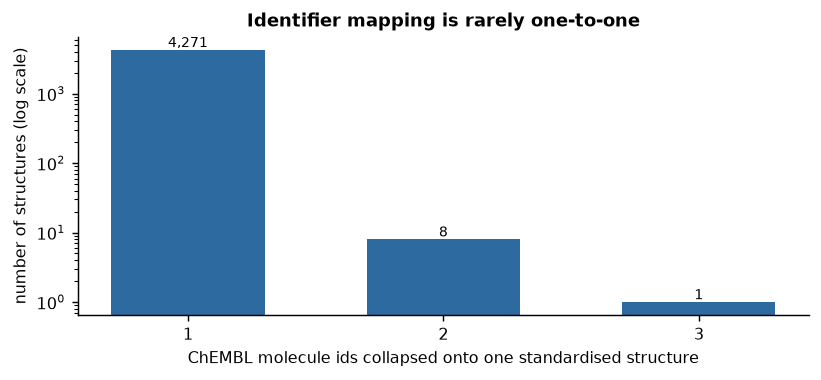

In [13]:
# Many-to-one mapping in the real curated table: how many ChEMBL ids per standardised structure?
cur = load_data("rock1_chembl_curated.csv")
cur["n_ids"] = cur["chembl_ids"].str.count(r"\|") + 1
counts = cur["n_ids"].value_counts().sort_index()
print("compounds (unique InChIKeys):", len(cur))
print("ChEMBL ids collapsed per structure:\n", counts.to_string(), sep="")
print("\nstructures built from more than one ChEMBL id:", int((cur['n_ids'] > 1).sum()),
      "| ids involved:", int(cur.loc[cur['n_ids'] > 1, 'n_ids'].sum()))
example = cur.loc[cur["n_ids"] > 1].iloc[0]
print("\nexample:", example["chembl_ids"], "->", example["inchikey"])

fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.bar(counts.index.astype(str), counts.to_numpy(), color="#2d6a9f", width=0.6)
ax.set_yscale("log")
for x, v in zip(counts.index.astype(str), counts.to_numpy()):
    ax.text(x, v * 1.1, f"{v:,}", ha="center", fontsize=8)
ax.set_xlabel("ChEMBL molecule ids collapsed onto one standardised structure")
ax.set_ylabel("number of structures (log scale)")
ax.set_title("Identifier mapping is rarely one-to-one")
fig.tight_layout()

<p class="caption"><b>Figure 5.</b> How many ChEMBL molecule identifiers collapse onto a single standardised structure in the curated ROCK1 table, on a logarithmic count axis. The overwhelming majority of structures come from exactly one identifier, but a non-trivial tail comes from two or more — salts, charge states and duplicate depositions of the same compound. Reporting "we studied <i>N</i> compounds" without saying whether <i>N</i> counts database identifiers or standardised structures is therefore ambiguous by a few per cent, and the curated table of this course counts structures.</p>

The practical danger of a many-to-one relationship is **row inflation**: joining two tables on a key that is not unique on either side multiplies rows. The next cell produces the error deliberately on the real tables.

In [14]:
# Row inflation: a join on a non-unique key, produced deliberately.
activities = raw[["activity_id", "molecule_chembl_id", "standard_type", "standard_value"]].copy()
# A 'parent structure' table: one row per ChEMBL id, with the InChIKey it maps to.
parents = (cur[["inchikey", "chembl_ids"]].assign(chembl_id=lambda d: d["chembl_ids"].str.split("|"))
             .explode("chembl_id")[["chembl_id", "inchikey"]])
print("activities rows           :", len(activities))
print("parent map rows           :", len(parents),
      "| unique chembl_id:", parents["chembl_id"].nunique(),
      "| unique inchikey:", parents["inchikey"].nunique())

correct = activities.merge(parents, left_on="molecule_chembl_id", right_on="chembl_id", how="left")
print("\ncorrect join (map is unique on chembl_id):", len(correct), "rows ->",
      "unchanged" if len(correct) == len(activities) else "INFLATED")

# Now the error: join on the structure instead, where the map is many-to-one.
inflated = activities.merge(parents, left_on="molecule_chembl_id", right_on="chembl_id", how="left") \
                     .merge(parents, on="inchikey", how="left", suffixes=("", "_dup"))
print("joining a second time on inchikey       :", len(inflated), "rows -> inflated by",
      f"{len(inflated) - len(activities):+,}", f"({100 * len(inflated) / len(activities) - 100:.1f}%)")
print("\nmean standard_value before:", round(activities['standard_value'].mean(), 1),
      "| after the inflating join:", round(inflated['standard_value'].mean(), 1))
print("the mean changed because duplicated rows are counted twice.")

activities rows           : 5089
parent map rows           : 4290 | unique chembl_id: 4290 | unique inchikey: 4280

correct join (map is unique on chembl_id): 5089 rows -> unchanged
joining a second time on inchikey       : 5172 rows -> inflated by +83 (1.6%)

mean standard_value before: 26388.7 | after the inflating join: 26064.5
the mean changed because duplicated rows are counted twice.


The row count grew and — the reason this matters — **the mean changed**, because compounds with several database identifiers now contribute several times to the average. No error was raised, the resulting table looks entirely normal, and every statistic computed from it is wrong by a few per cent in an unpredictable direction. The defences are mechanical and you should apply all three: assert the expected row count after every merge (`assert len(merged) == len(left)` for a left join on a unique key), check `df[key].is_unique` on the side that should be unique *before* merging, and prefer `validate="m:1"` in `pandas.merge`, which raises if the relationship is not what you declared.

<div class="box key"><h4>The identifier rules of this group</h4>
<p>Store the <em>structure-based</em> identifier (InChIKey) as the row key of a compound table, keep the database identifiers as a separate column, and never deduplicate on the skeleton block alone. For proteins store the UniProt accession, not the gene symbol — symbols are ambiguous across species and change over time. Record the <em>version</em> of every mapping table you use. And whenever a join is performed, state in the code what cardinality you expect and let pandas verify it.</p></div>

## 6. SQL in one hour

A folder of CSV files is a database with no schema, no types, no constraints, no indexes and no query language. A **relational database** supplies all five. The relational model<sup class="c"><a href="#r24">[24]</a></sup> is simple enough to state in three sentences: data live in *tables* (relations) of *rows* (tuples) with named, typed *columns*; one column (or a combination) is the **primary key**, unique per row; a column referring to another table's key is a **foreign key**. Every query is then a combination of selecting rows, choosing columns, joining tables on keys, and grouping.

**SQLite** is the right database for a thesis project: a single file, no server, available in the Python standard library, and one of the most widely deployed pieces of software in existence<sup class="c"><a href="#r25">[25]</a></sup>. ChEMBL itself is distributed as a SQLite dump, so the SQL you write here is the SQL you would run against the whole database. We build a three-table database from the frozen course files.

In [15]:
# Build an in-notebook SQLite database from the frozen CSVs: activities, compounds, assays.
con = sqlite3.connect(SCRATCH / "rock1.sqlite")

activities_tbl = raw[["activity_id", "molecule_chembl_id", "assay_chembl_id", "standard_type",
                      "standard_relation", "standard_value", "standard_units", "pchembl_value"]]
compounds_tbl = (raw[["molecule_chembl_id", "canonical_smiles", "pref_name", "max_phase", "molecule_type"]]
                 .drop_duplicates("molecule_chembl_id"))
assays_tbl = (raw[["assay_chembl_id", "assay_type", "assay_description", "document_chembl_id", "bao_label"]]
              .drop_duplicates("assay_chembl_id"))

activities_tbl.to_sql("activities", con, index=False, if_exists="replace")
compounds_tbl.to_sql("compounds", con, index=False, if_exists="replace")
assays_tbl.to_sql("assays", con, index=False, if_exists="replace")

print("tables and row counts:")
for name in ["activities", "compounds", "assays"]:
    n = pd.read_sql(f"SELECT COUNT(*) AS n FROM {name}", con)["n"].iloc[0]
    cols = [r[1] for r in con.execute(f"PRAGMA table_info({name})")]
    print(f"  {name:<11} {n:>5} rows | columns: {', '.join(cols)}")
print("\ndatabase file size: %.2f MB" % ((SCRATCH / 'rock1.sqlite').stat().st_size / 1e6))
print("primary keys here are activity_id, molecule_chembl_id and assay_chembl_id;")
print("activities.molecule_chembl_id and activities.assay_chembl_id are the foreign keys.")

tables and row counts:
  activities   5089 rows | columns: activity_id, molecule_chembl_id, assay_chembl_id, standard_type, standard_relation, standard_value, standard_units, pchembl_value
  compounds    4312 rows | columns: molecule_chembl_id, canonical_smiles, pref_name, max_phase, molecule_type
  assays        276 rows | columns: assay_chembl_id, assay_type, assay_description, document_chembl_id, bao_label

database file size: 0.77 MB
primary keys here are activity_id, molecule_chembl_id and assay_chembl_id;
activities.molecule_chembl_id and activities.assay_chembl_id are the foreign keys.


Three tables, one row per thing, no repetition: the assay description appears once in `assays` instead of once per measurement, which is what **normalisation** means and why the database file is smaller than the CSV it came from. The next cell is the SQL vocabulary in one pass — `SELECT` which columns, `FROM` which table, `WHERE` which rows, `ORDER BY` in which order, `LIMIT` how many.

In [16]:
# SELECT / WHERE / ORDER BY / LIMIT: the ten most potent exactly-measured IC50 records.
q1 = '''
SELECT a.molecule_chembl_id, c.pref_name, a.standard_value AS ic50_nM, a.assay_chembl_id
FROM activities AS a
JOIN compounds  AS c ON c.molecule_chembl_id = a.molecule_chembl_id
WHERE a.standard_type = 'IC50'
  AND a.standard_relation = '='
  AND a.standard_value IS NOT NULL
ORDER BY a.standard_value ASC
LIMIT 10
'''
top10 = pd.read_sql(q1, con)
print(top10.to_string(index=False))
print("\nmost potent recorded IC50: %.3f nM" % top10['ic50_nM'].min(),
      "| named compounds among the top 10:", int(top10['pref_name'].notna().sum()))

molecule_chembl_id     pref_name  ic50_nM assay_chembl_id
     CHEMBL5974947           NaN    0.000   CHEMBL5738411
     CHEMBL4107027           NaN    0.200   CHEMBL3889185
     CHEMBL5901861           NaN    0.200   CHEMBL5739165
     CHEMBL3902471           NaN    0.260   CHEMBL3889185
     CHEMBL3961538           NaN    0.390   CHEMBL3889185
     CHEMBL5987641           NaN    0.400   CHEMBL5738411
     CHEMBL5739910           NaN    0.400   CHEMBL5738411
     CHEMBL5739910           NaN    0.400   CHEMBL5738411
     CHEMBL3949136           NaN    0.430   CHEMBL3889185
      CHEMBL388978 STAUROSPORINE    0.444   CHEMBL4720568

most potent recorded IC50: 0.000 nM | named compounds among the top 10: 1


<p class="caption"><b>Table (Section 6).</b> The ten most potent exactly-measured IC50 records in the frozen snapshot, obtained with one SQL statement that joins the activity table to the compound table. Note the <code>IS NOT NULL</code> condition: in SQL, <code>NULL</code> is not a value but the absence of one, so <code>standard_value = NULL</code> is never true — comparisons with <code>NULL</code> yield <code>NULL</code>, which is not <code>TRUE</code>. This is the single most common SQL mistake among newcomers.</p>

Read the first row of that table before you celebrate: the smallest "IC50" in the snapshot is printed as <code>0.000 nM</code>, which is not a potency but a defect — a record whose value is literally zero, and which ChEMBL itself flags in its <code>data_validity_comment</code> column as being outside the typical range. A concentration of zero has no logarithm, so it would propagate as an infinity into every pActivity computed from it. This is the raw table doing its job as a teaching dataset, and it illustrates the rule that a query is only as trustworthy as its filters: the honest version of this question adds <code>AND a.standard_value &gt; 0</code> and excludes flagged records, which is exactly what steps 4 and 7 of the reference curation protocol do before the curated table of <a href="../U6_Data_Quality/index.html">Unit 6</a> is produced. Quality problems of this kind are endemic to public chemistry databases rather than peculiar to this target<sup class="c"><a href="#r31">[31]</a></sup>.

### 6.1 A worked example by hand: inner join, left join, and what `COUNT` counts

Joins are best learned on tables small enough to trace with a pencil. Take three compounds and three measurements:

**`compounds`**

| compound_id | name |
|---|---|
| C1 | fasudil |
| C2 | Y-27632 |
| C3 | ripasudil |

**`activities`**

| activity_id | compound_id | ic50_nM |
|---|---|---|
| A1 | C1 | 25 |
| A2 | C1 | 30 |
| A3 | C2 | 500 |

Tracing by hand:

- **`INNER JOIN` on `compound_id`** keeps only pairs that exist on both sides: A1–C1, A2–C1, A3–C2 → **3 rows**. C3 disappears, because it has no measurement. If you then count compounds in the result you get **2**, not 3 — the inner join silently dropped the untested compound.
- **`LEFT JOIN` from `compounds`** keeps every compound and fills the missing side with `NULL`: C1–A1, C1–A2, C2–A3, C3–`NULL` → **4 rows**.
- On that left join, `COUNT(*)` **per compound** gives C1 → 2, C2 → 1, C3 → **1**, because the row for C3 exists even though its measurement is `NULL`. But `COUNT(activity_id)` gives C1 → 2, C2 → 1, C3 → **0**, because `COUNT(column)` ignores `NULL`s. Only the second is the answer to "how many measurements does this compound have".

That last distinction is the trap: a query that reports "every compound has at least one measurement" is usually a `COUNT(*)` over a left join. The cell below confirms all three results in SQL and reproduces them with `pandas.merge`.

In [17]:
# Confirming the hand-traced joins in SQL, and reproducing them in pandas.
small_c = pd.DataFrame({"compound_id": ["C1", "C2", "C3"],
                        "name": ["fasudil", "Y-27632", "ripasudil"]})
small_a = pd.DataFrame({"activity_id": ["A1", "A2", "A3"],
                        "compound_id": ["C1", "C1", "C2"], "ic50_nM": [25, 30, 500]})
small_c.to_sql("small_compounds", con, index=False, if_exists="replace")
small_a.to_sql("small_activities", con, index=False, if_exists="replace")

inner = pd.read_sql("SELECT c.compound_id, c.name, a.activity_id, a.ic50_nM "
                    "FROM small_compounds c JOIN small_activities a USING (compound_id)", con)
left = pd.read_sql("SELECT c.compound_id, c.name, a.activity_id, a.ic50_nM "
                   "FROM small_compounds c LEFT JOIN small_activities a USING (compound_id)", con)
counts = pd.read_sql("SELECT c.compound_id, COUNT(*) AS count_star, COUNT(a.activity_id) AS count_col "
                     "FROM small_compounds c LEFT JOIN small_activities a USING (compound_id) "
                     "GROUP BY c.compound_id ORDER BY c.compound_id", con)

print("INNER JOIN ->", len(inner), "rows (hand-traced: 3); compounds present:",
      inner['compound_id'].nunique(), "(hand-traced: 2)")
print("LEFT  JOIN ->", len(left), "rows (hand-traced: 4)")
print("\nCOUNT(*) versus COUNT(activity_id) per compound:")
print(counts.to_string(index=False))

pd_left = small_c.merge(small_a, on="compound_id", how="left")
pd_counts = (pd_left.groupby("compound_id", observed=True)
                    .agg(count_star=("compound_id", "size"), count_col=("activity_id", "count"))
                    .reset_index())
print("\npandas reproduces the same table:", pd_counts.equals(counts))
print("hand = SQL = pandas:", list(counts['count_col']) == [2, 1, 0] == list(pd_counts['count_col']))

INNER JOIN -> 3 rows (hand-traced: 3); compounds present: 2 (hand-traced: 2)
LEFT  JOIN -> 4 rows (hand-traced: 4)

COUNT(*) versus COUNT(activity_id) per compound:
compound_id  count_star  count_col
         C1           2          2
         C2           1          1
         C3           1          0

pandas reproduces the same table: True
hand = SQL = pandas: True


All three agree with the pencil: three rows from the inner join, four from the left join, and `COUNT(activity_id)` giving zero for the untested compound where `COUNT(*)` gives one. Note the pandas correspondence, which is worth memorising because it makes SQL readable to a pandas user and vice versa: `WHERE` is a boolean mask, `JOIN` is `merge`, `GROUP BY ... agg` is `groupby(...).agg(...)`, `ORDER BY` is `sort_values`, `LIMIT` is `head`, `COUNT(*)` is `size` and `COUNT(col)` is `count`. The correspondence is not accidental — pandas was designed with the relational operations in mind<sup class="c"><a href="#r34">[34]</a></sup>.

assay_type             bao_label  n_records  n_compounds  n_documents  mean_nM  n_exact
         B single protein format       3155         2677          195  36476.7     2404
         F          assay format       1020         1003            2   5659.0      502
         B          assay format        501          464           19   8577.7      278
         B    subcellular format        243          243            1  28313.0       18
         B     cell-based format        161          146           17  13189.8      125


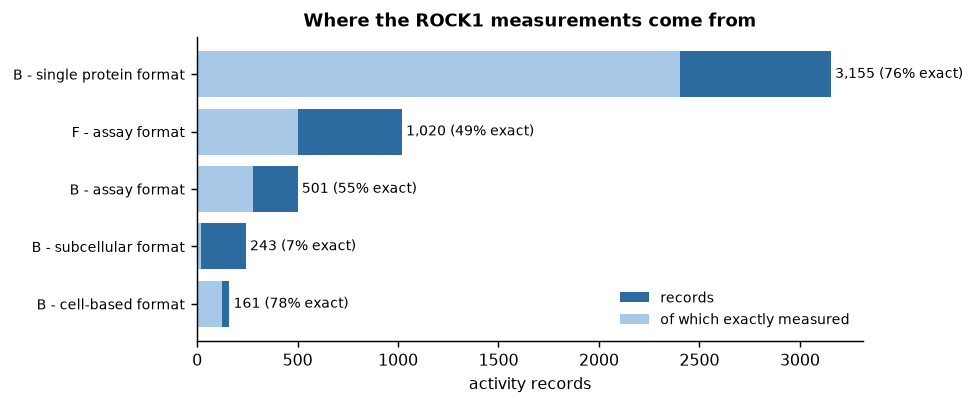

In [18]:
# GROUP BY and HAVING on the real tables: which assay types carry the data?
q2 = '''
SELECT s.assay_type,
       s.bao_label,
       COUNT(*)                                   AS n_records,
       COUNT(DISTINCT a.molecule_chembl_id)       AS n_compounds,
       COUNT(DISTINCT s.document_chembl_id)       AS n_documents,
       ROUND(AVG(a.standard_value), 1)            AS mean_nM,
       SUM(CASE WHEN a.standard_relation = '=' THEN 1 ELSE 0 END) AS n_exact
FROM activities AS a
JOIN assays     AS s ON s.assay_chembl_id = a.assay_chembl_id
GROUP BY s.assay_type, s.bao_label
HAVING COUNT(*) >= 10
ORDER BY n_records DESC
'''
by_assay = pd.read_sql(q2, con)
print(by_assay.to_string(index=False))

fig, ax = plt.subplots(figsize=(7.6, 3.2))
labels = [f"{t} - {b}" for t, b in zip(by_assay["assay_type"], by_assay["bao_label"])]
y = np.arange(len(labels))
ax.barh(y, by_assay["n_records"], color="#2d6a9f", label="records")
ax.barh(y, by_assay["n_exact"], color="#a8c8e8", label="of which exactly measured")
for i, (n, e) in enumerate(zip(by_assay["n_records"], by_assay["n_exact"])):
    ax.text(n + 20, i, f"{n:,} ({100*e/n:.0f}% exact)", va="center", fontsize=7.6)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=7.6); ax.invert_yaxis()
ax.set_xlabel("activity records"); ax.set_title("Where the ROCK1 measurements come from")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()

<p class="caption"><b>Figure 6.</b> Activity records per assay type and BioAssay Ontology label, from the <code>GROUP BY … HAVING</code> query above, with the exactly-measured subset shown in the lighter shade and its percentage annotated. Binding assays (<code>B</code>) and functional assays (<code>F</code>) measure different things — displacement of a ligand versus inhibition of enzymatic activity — and mixing them in one regression target is a modelling decision that must be made explicitly, not inherited from a download. The <code>HAVING</code> clause filtered out the long tail of assay categories with fewer than ten records; note that <code>HAVING</code> filters <em>groups</em> after aggregation, whereas <code>WHERE</code> filters rows before it.</p>

### 6.2 Subqueries, and the question a folder of CSVs cannot answer

A **subquery** is a query used as a table. The pattern below — find the compounds measured in at least three distinct documents, then report their activity spread — is the kind of question that requires two passes over the data and is tedious in pandas but natural in SQL.

In [19]:
# A subquery: compounds measured in >= 3 distinct documents, with their IC50 spread.
q3 = '''
SELECT m.molecule_chembl_id,
       c.pref_name,
       m.n_documents,
       m.n_records,
       ROUND(m.min_nM, 1) AS min_nM,
       ROUND(m.max_nM, 1) AS max_nM,
       ROUND(m.max_nM / m.min_nM, 1) AS fold_spread
FROM (
    SELECT a.molecule_chembl_id,
           COUNT(DISTINCT s.document_chembl_id) AS n_documents,
           COUNT(*)                            AS n_records,
           MIN(a.standard_value)               AS min_nM,
           MAX(a.standard_value)               AS max_nM
    FROM activities a
    JOIN assays s ON s.assay_chembl_id = a.assay_chembl_id
    WHERE a.standard_type = 'IC50' AND a.standard_relation = '=' AND a.standard_value > 0
    GROUP BY a.molecule_chembl_id
) AS m
JOIN compounds c ON c.molecule_chembl_id = m.molecule_chembl_id
WHERE m.n_documents >= 3
ORDER BY fold_spread DESC
LIMIT 8
'''
spread = pd.read_sql(q3, con)
print(spread.to_string(index=False))
print("\nlargest fold spread between two published IC50 values for the same compound: %.0f-fold"
      % spread['fold_spread'].max())
print("that is %.1f log units - larger than the effect most QSAR models are asked to predict."
      % np.log10(spread['fold_spread'].max()))

molecule_chembl_id     pref_name  n_documents  n_records  min_nM  max_nM  fold_spread
      CHEMBL220241   GSK-269962A            5          6     1.6  3000.0       1875.0
     CHEMBL2005186   BELUMOSUDIL            8          9    24.0 24000.0       1000.0
      CHEMBL559147       Y-27632            7          8    32.9 30000.0        913.0
     CHEMBL1956071           NaN            4          5     5.6  3000.0        535.7
     CHEMBL1971943       BAY-549            9          9     0.6    65.0        108.3
     CHEMBL2023157           NaN            3          3    85.0  9070.0        106.7
      CHEMBL388978 STAUROSPORINE            7          7     0.4    19.0         42.8
      CHEMBL571948       Y-39983            3          3     3.6   120.0         33.3

largest fold spread between two published IC50 values for the same compound: 1875-fold
that is 3.3 log units - larger than the effect most QSAR models are asked to predict.


<p class="caption"><b>Table (Section 6.2).</b> Compounds whose IC50 was measured in at least three distinct publications, ordered by the ratio between their largest and smallest reported value. The printed fold spread is the experimental reality this course keeps returning to: independent laboratories measuring the same compound against the same target disagree, sometimes by more than an order of magnitude<sup class="c"><a href="#r26">[26]</a></sup><sup class="c"><a href="#r27">[27]</a></sup><sup class="c"><a href="#r28">[28]</a></sup>. Units 6 and 7 decide what to do about it — aggregate with a median, keep the spread as a column, and never report a model error smaller than the data's own noise.</p>

### 6.3 Indexes: why a database beats a folder

An **index** is a sorted structure that lets the database find rows by a key without scanning the table. Creating one costs disk and slows writes; it changes a linear scan into a logarithmic lookup. The next cell measures it on a table of about a hundred thousand rows.

table: 101,780 rows
40 lookups without an index:    174.2 ms  (4.35 ms each)
building the index         :     65.6 ms
40 lookups with the index  :      0.3 ms  (0.01 ms each)
speed-up: 572x; the index paid for itself after 15 lookups


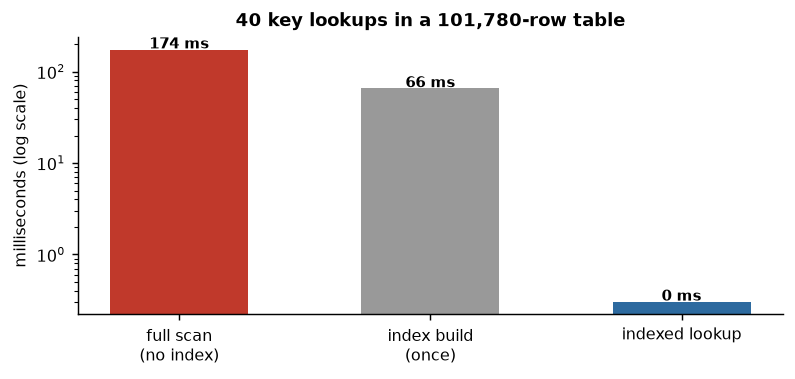

In [20]:
# The cost of a scan versus the cost of an index, measured.
wide_tbl = pd.concat([activities_tbl] * 20, ignore_index=True)
wide_tbl.to_sql("activities_big", con, index=False, if_exists="replace")
probe_ids = raw["molecule_chembl_id"].dropna().sample(40, random_state=0).tolist()

def timed_lookups(ids):
    t0 = time.perf_counter()
    for mid in ids:
        con.execute("SELECT COUNT(*) FROM activities_big WHERE molecule_chembl_id = ?", (mid,)).fetchone()
    return time.perf_counter() - t0

no_index = timed_lookups(probe_ids)
t0 = time.perf_counter()
con.execute("CREATE INDEX IF NOT EXISTS idx_mol ON activities_big(molecule_chembl_id)")
build = time.perf_counter() - t0
with_index = timed_lookups(probe_ids)

print(f"table: {len(wide_tbl):,} rows")
print(f"40 lookups without an index: {no_index*1000:8.1f} ms  ({no_index/40*1000:.2f} ms each)")
print(f"building the index         : {build*1000:8.1f} ms")
print(f"40 lookups with the index  : {with_index*1000:8.1f} ms  ({with_index/40*1000:.2f} ms each)")
print(f"speed-up: {no_index/with_index:.0f}x; the index paid for itself after "
      f"{build/((no_index-with_index)/40):.0f} lookups")

fig, ax = plt.subplots(figsize=(6.2, 3.0))
bars = ax.bar(["full scan\n(no index)", "index build\n(once)", "indexed lookup"],
              [no_index * 1000, build * 1000, with_index * 1000],
              color=["#c0392b", "#999999", "#2d6a9f"], width=0.55)
for b, v in zip(bars, [no_index * 1000, build * 1000, with_index * 1000]):
    ax.text(b.get_x() + b.get_width() / 2, v * 1.03, f"{v:.0f} ms", ha="center", fontsize=8.5, fontweight="bold")
ax.set_yscale("log"); ax.set_ylabel("milliseconds (log scale)")
ax.set_title(f"40 key lookups in a {len(wide_tbl):,}-row table")
fig.tight_layout()

<p class="caption"><b>Figure 7.</b> Time for forty key lookups in a table of about a hundred thousand rows, before and after creating an index on the lookup column, with the one-off index build shown in grey (logarithmic axis). The measured speed-up and the break-even point are printed above the figure: the index repays its construction cost after a handful of queries. This is the concrete answer to "when does a database beat a folder of CSV files?" — when you query the same data repeatedly by key, when it does not fit in memory, when several processes read it at once, or when you need the types and constraints a schema enforces. For a single pass over a table that fits in RAM, pandas is simpler and faster.</p>

### 6.4 The same question, twice

The final SQL exercise is the one the syllabus asks for: answer one question in both systems and compare the answers row by row.

In [21]:
# One question, two implementations: 'per measurement type, how many exact records and what spread?'
question_sql = '''
SELECT standard_type,
       COUNT(*)              AS n,
       SUM(CASE WHEN standard_relation = '=' THEN 1 ELSE 0 END) AS n_exact,
       ROUND(AVG(standard_value), 3) AS mean_nM,
       ROUND(MIN(standard_value), 3) AS min_nM,
       ROUND(MAX(standard_value), 3) AS max_nM
FROM activities
WHERE standard_value IS NOT NULL
GROUP BY standard_type
ORDER BY n DESC
'''
t0 = time.perf_counter(); sql_answer = pd.read_sql(question_sql, con); t_sql = time.perf_counter() - t0

t0 = time.perf_counter()
d = activities_tbl[activities_tbl["standard_value"].notna()]
pandas_answer = (d.groupby("standard_type", observed=True)
                   .agg(n=("standard_value", "size"),
                        n_exact=("standard_relation", lambda s: int((s == "=").sum())),
                        mean_nM=("standard_value", "mean"),
                        min_nM=("standard_value", "min"),
                        max_nM=("standard_value", "max"))
                   .sort_values("n", ascending=False).reset_index().round(3))
t_pandas = time.perf_counter() - t0

print("SQL:\n", sql_answer.to_string(index=False), sep="")
print("\npandas:\n", pandas_answer.to_string(index=False), sep="")
same_shape = sql_answer.shape == pandas_answer.shape
same_values = all(np.allclose(sql_answer[c].to_numpy(float), pandas_answer[c].to_numpy(float), atol=1e-3)
                  for c in ["n", "n_exact", "mean_nM", "min_nM", "max_nM"])
same_keys = list(sql_answer["standard_type"]) == list(pandas_answer["standard_type"])
print("\nidentical shape:", same_shape, "| identical keys:", same_keys, "| identical values:", same_values)
print("timing on this table: SQL %.1f ms vs pandas %.1f ms" % (t_sql * 1000, t_pandas * 1000))

SQL:
standard_type    n  n_exact   mean_nM  min_nM     max_nM
         IC50 3237     2353 36078.751    0.00 30000000.0
           Ki 1480      920  5952.212    0.15   100000.0
           Kd  346       63 23149.319    0.28   470000.0

pandas:
standard_type    n  n_exact   mean_nM  min_nM     max_nM
         IC50 3237     2353 36078.751    0.00 30000000.0
           Ki 1480      920  5952.212    0.15   100000.0
           Kd  346       63 23149.319    0.28   470000.0

identical shape: True | identical keys: True | identical values: True
timing on this table: SQL 1.7 ms vs pandas 3.6 ms


The two answers agree on every key and every value to three decimals — which is the point of the exercise. SQL and pandas are two syntaxes for the same relational operations, and the choice between them is pragmatic: SQL when the data live in a database, when the query is a join of several tables, or when the table does not fit in memory; pandas when the data are already loaded, when the operation is not expressible relationally (a bootstrap, a model fit, a plot), or when it is one step of a longer Python pipeline. The timing printed above is for one table that fits comfortably in memory, where the difference is of no consequence — and a measurement, not a general claim.

maximum absolute difference between the two answers: 0.0


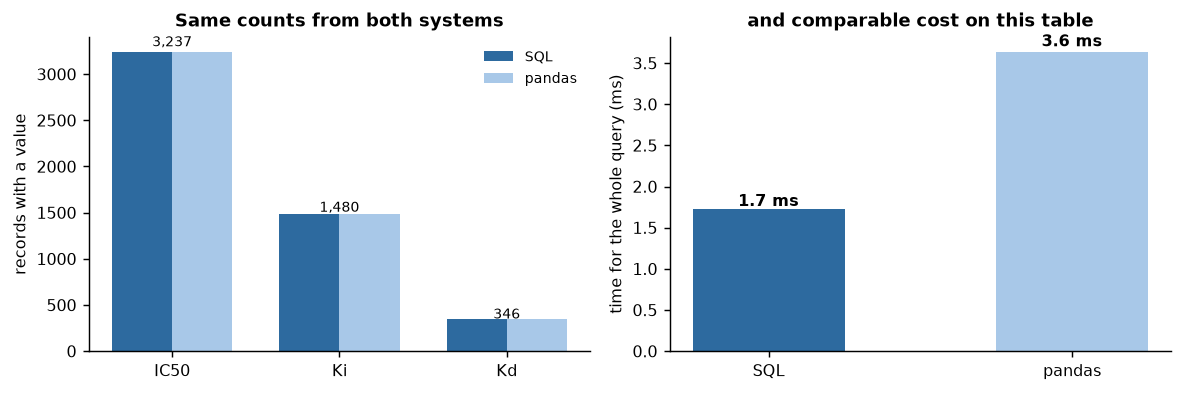

In [22]:
# Figure: the two answers, side by side - the agreement made visible.
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.1))
x = np.arange(len(sql_answer))
axes[0].bar(x - 0.18, sql_answer["n"], width=0.36, color="#2d6a9f", label="SQL")
axes[0].bar(x + 0.18, pandas_answer["n"], width=0.36, color="#a8c8e8", label="pandas")
axes[0].set_xticks(x); axes[0].set_xticklabels(sql_answer["standard_type"])
axes[0].set_ylabel("records with a value"); axes[0].set_title("Same counts from both systems")
axes[0].legend(frameon=False, fontsize=8)
for i, (a_, b_) in enumerate(zip(sql_answer["n"], pandas_answer["n"])):
    axes[0].text(i, max(a_, b_) * 1.02, f"{a_:,}", ha="center", fontsize=8)
axes[1].bar(["SQL", "pandas"], [t_sql * 1000, t_pandas * 1000], color=["#2d6a9f", "#a8c8e8"], width=0.5)
for i, v in enumerate([t_sql * 1000, t_pandas * 1000]):
    axes[1].text(i, v * 1.02, f"{v:.1f} ms", ha="center", fontsize=9, fontweight="bold")
axes[1].set_ylabel("time for the whole query (ms)"); axes[1].set_title("and comparable cost on this table")
fig.tight_layout()
print("maximum absolute difference between the two answers:",
      float(np.max(np.abs(sql_answer[["n", "n_exact", "mean_nM"]].to_numpy(float)
                          - pandas_answer[["n", "n_exact", "mean_nM"]].to_numpy(float)))))

<p class="caption"><b>Figure 8.</b> Left: the record count per measurement type as computed by SQL (dark) and by pandas (light) — the bars are identical, which is the verification the syllabus asks for, and the printed maximum absolute difference across the compared columns is zero to rounding. Right: the wall-clock cost of each implementation on this in-memory-sized table. Neither system is "the fast one"; what differs is where the data already are and how the question is phrased.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Write the SQL that answers: "for each assay type, how many distinct compounds have at least two exactly-measured IC50 records in different documents?" You will need a subquery, a <code>GROUP BY</code> with <code>HAVING</code>, and a join to <code>assays</code>. Then write the pandas equivalent and compare the two results with <code>np.allclose</code>, as above. Finally, add an index on <code>activities(standard_type, standard_relation)</code> and re-time your query: does it help, and why does an index on a column with three distinct values help less than an index on a compound identifier?</p></div>

## 7. Terms of use, licences and when scraping is not acceptable

Three obligations attach to data you did not generate, and all three are part of the method rather than of the paperwork.

**The licence governs redistribution.** ChEMBL is CC BY-SA 3.0, so a derived table must carry the same licence (Unit 2); PubChem's own content is public domain, but individual depositor submissions may carry their own terms; the PDB is open; GEO data are public but the associated publications are not. Record the licence of every source in your manifest before building a derived table.

**The terms of use govern access.** Public APIs publish rate limits and acceptable-use policies. NCBI, for instance, limits anonymous E-utilities requests and asks for an identifying tool name and contact address. Exceeding the limits gets your institution's address blocked — which affects your colleagues, not only you.

**`robots.txt` governs crawling.** A web server publishes `/robots.txt` to declare which paths automated clients may fetch; the format is standardised as RFC 9309<sup class="c"><a href="#r29">[29]</a></sup>. Python's standard library parses it, so there is no excuse for not checking. The next cell demonstrates the parser on a representative policy.

In [23]:
# Parsing a robots.txt policy (text written in-cell, not fetched) and honouring it.
policy = '''User-agent: *
Disallow: /private/
Disallow: /cgi-bin/
Crawl-delay: 5

User-agent: GreedyBot
Disallow: /
'''
(SCRATCH / "robots.txt").write_text(policy, encoding="utf-8")
parser = urllib.robotparser.RobotFileParser()
parser.parse(policy.splitlines())

tests = [("*", "https://example.org/data/activities.csv"),
         ("*", "https://example.org/private/internal.csv"),
         ("*", "https://example.org/cgi-bin/query"),
         ("GreedyBot", "https://example.org/data/activities.csv")]
for agent, url in tests:
    print(f"  {agent:<10} {url:<48} -> {'allowed' if parser.can_fetch(agent, url) else 'DISALLOWED'}")
print("\ncrawl delay requested for a generic client:", parser.crawl_delay("*"), "seconds")
print("\nAnd the rule no file can express: if a bulk download or an API exists, use it instead of crawling.")

  *          https://example.org/data/activities.csv          -> allowed
  *          https://example.org/private/internal.csv         -> DISALLOWED
  *          https://example.org/cgi-bin/query                -> DISALLOWED
  GreedyBot  https://example.org/data/activities.csv          -> DISALLOWED

crawl delay requested for a generic client: 5 seconds

And the rule no file can express: if a bulk download or an API exists, use it instead of crawling.


The parser answers per user agent and per path, and it reports the requested crawl delay — which a polite client sleeps for between requests. But the decisive judgement is not technical. Scraping is **not acceptable** when an API or a bulk download exists (you are generating load for no reason), when the terms of use forbid it, when the content is behind authentication or a paywall, when the data are personal, or when your crawl would degrade a service other researchers depend on. In this laboratory, the order of preference is always: bulk download, then official API client, then hand-written API calls, and scraping only for a page that exists nowhere else — after asking.

<div class="box bridge"><h4>Bridge — where the data go next</h4>
<p>This unit filled <code>data/raw/</code>. <a href="../U4_Tidy_Data/index.html">Unit 4</a> reshapes what arrived into a tidy table<sup class="c"><a href="#r30">[30]</a></sup> — one row per observation, one column per variable — and <a href="../U6_Data_Quality/index.html">Unit 6</a> curates it into the modelling table used from Unit 7 onwards, with a logged decision for every record it removes. <a href="../U2_Reproducibility/index.html">Unit 2</a> is what makes this unit's downloads citable: manifest, checksum, licence, DOI. <a href="../U21_Omics/index.html">Unit 21</a> returns to FASTA and GEO, <a href="../U20_MD_Analytics/index.html">Unit 20</a> to trajectory formats, and <a href="../U24_Software_Engineering/index.html">Unit 24</a> turns the API client of Section 4 into a tested, installable module. In the sister courses, the cheminformatics elective covers <a href="../../../Cheminformatics/U3_SMILES_InChI_Formats/index.html">SMILES and InChI</a> and <a href="../../../Cheminformatics/U6_Databases/index.html">chemical databases</a> in chemical depth, while BGM324 shows what is done with the structures retrieved from the PDB in <a href="../../../BGM324/02_Protein_Structure_Prediction/index.html">structure prediction</a> and <a href="../../../BGM324/03_Molecular_Docking/index.html">docking</a>.</p></div>

In [24]:
# Close the database and remove every temporary artefact.
con.close()
shutil.rmtree(SCRATCH, ignore_errors=True)
print("scratch directory removed:", not SCRATCH.exists())
print("the frozen tables in ../data/ were read, never modified:",
      Path(data_path('rock1_chembl_raw.csv')).exists())

scratch directory removed: True
the frozen tables in ../data/ were read, never modified: True


## 8. Summary

You should now be able to explain, without notes:

- The four axes along which file formats differ, and which format this group uses for raw downloads, intermediate tables, large numeric arrays and nested metadata — with the measurement that justifies each choice.
- Exactly what a CSV loses, the four kinds of value that do not survive a round trip, and the three `read_csv` arguments that defend against it.
- Why a columnar format makes "two of twenty-five columns" cheap and a CSV does not.
- What SMILES, SDF, FASTA and PDB/mmCIF each store, and why PDB must be parsed by column position rather than by splitting on whitespace.
- The anatomy of an HTTP request, the meaning of the status codes that matter, and the four disciplines of a well-behaved client: timeout, pagination, backoff with jitter, cache.
- Why a live call must always print its own provenance, and why this course's notebooks read frozen files.
- The identifier systems of the field, the three blocks of an InChIKey, and why deduplicating on the skeleton block merges enantiomers.
- What row inflation is, how a non-unique join key changes a mean, and the three defences against it.
- The relational model in three sentences; `SELECT`, `WHERE`, `JOIN`, `GROUP BY`, `HAVING`, subqueries; why `NULL` comparisons are never true; and the difference between `COUNT(*)` and `COUNT(column)` on a left join.
- When a database beats a folder of CSV files, and what an index costs and buys.
- The licence, terms-of-use and `robots.txt` obligations, and the order of preference: bulk download, official client, hand-written calls, and scraping only as a last resort after asking.

## 9. Self-assessment

<details><summary>Q1. A collaborator sends a CSV in which a compound identifier column has lost its leading zeros and a comment column has become empty. Explain both, and give the <code>read_csv</code> call that would have prevented them.</summary>
<p>CSV stores characters, not types, so the reader inferred an integer dtype for the identifier column (dropping leading zeros) and treated the literal string <code>NA</code> as missing. Prevent both with explicit arguments: <code>pd.read_csv(path, dtype={"plate_well": "string"}, keep_default_na=False, na_values=[""])</code>. Better still, exchange the file as Parquet, which carries a schema and round-trips exactly.</p></details>

<details><summary>Q2. Why is reading two of twenty-five columns dramatically faster in Parquet but only slightly faster in CSV?</summary>
<p>Parquet stores each column as a separate compressed block with its own metadata, so the reader seeks to two blocks and skips the rest of the file. A CSV reader must scan every byte of every line to locate the field separators, so restricting columns saves only the construction of the unwanted Series, not the parsing. The measured ratios are printed in Section 2.</p></details>

<details><summary>Q3. You must store a 2048-bit fingerprint for ten million molecules. Which format, and why not CSV?</summary>
<p>A binary array format — HDF5 or <code>.npz</code> — because the data are a homogeneous numeric matrix, and because a CSV would store each bit as a character plus a separator, inflating the file by an order of magnitude and making every read a parse. HDF5 also supports chunking and compression, so slices can be read without loading the whole matrix.</p></details>

<details><summary>Q4. Which HTTP status codes should a client retry, which should it never retry, and why does the backoff need jitter?</summary>
<p>Retry 429 and 5xx (transient: rate limit or server failure). Never retry 400, 401, 403 or 404 — the request itself is wrong, so repeating it only adds load. Jitter decorrelates the retries of many clients that failed at the same moment, preventing a synchronised second wave that would knock the service over again.</p></details>

<details><summary>Q5. This notebook calls a live API but its results are reproducible. How?</summary>
<p>Because the live call is wrapped in <code>try/except</code> with a timeout, its result is cached, its provenance is printed, and every number used downstream comes from the frozen, checksummed file in <code>../data/</code>. The network call serves to <em>date</em> the snapshot — comparing the live record count with the frozen one — not to produce the analysis.</p></details>

<details><summary>Q6. Two molecules share the first 14 characters of their InChIKey. What do you know, and what must you not conclude?</summary>
<p>You know they have the same constitutional skeleton — the same atoms connected in the same way. You must not conclude they are the same compound: the second block encodes stereochemistry and isotopes, so enantiomers and diastereomers share the skeleton block while differing pharmacologically, and the final character encodes protonation state. Match on the full key.</p></details>

<details><summary>Q7. After a merge, your table has 7 % more rows than the left table and the mean of a value column has changed. What happened, and what are the three defences?</summary>
<p>The join key was not unique on the right-hand side, so matching rows were duplicated (row inflation), and duplicated rows now contribute multiple times to the mean. Defences: assert the row count after the merge; check <code>df[key].is_unique</code> on the side that must be unique before merging; and declare the expected cardinality with <code>validate="m:1"</code> so pandas raises instead of inflating.</p></details>

<details><summary>Q8. Why does <code>WHERE standard_value = NULL</code> return no rows, and what is the correct clause?</summary>
<p>Because <code>NULL</code> represents the absence of a value, and any comparison with it evaluates to <code>NULL</code>, which is not <code>TRUE</code>, so no row satisfies the condition. Use <code>IS NULL</code> or <code>IS NOT NULL</code>. The same logic explains why <code>NULL</code> rows vanish from inner joins and why aggregate functions ignore them.</p></details>

<details><summary>Q9. On a left join of compounds to activities, <code>COUNT(*)</code> reports 1 for a compound with no measurements. Why, and which function should you use?</summary>
<p>The left join produced one row for that compound with <code>NULL</code> in the activity columns, and <code>COUNT(*)</code> counts rows regardless of content. <code>COUNT(activity_id)</code> ignores <code>NULL</code>s and correctly reports 0. This is the hand-traced result of Section 6.1, confirmed in SQL and in pandas.</p></details>

<details><summary>Q10. When is a database the right tool, and when is pandas?</summary>
<p>A database when the data are queried repeatedly by key, when they exceed memory, when several processes read them concurrently, or when types and constraints must be enforced; an index then turns scans into lookups (Figure 7). pandas when the table fits in memory and the work is a single pass, or when the operation is not relational — fitting a model, bootstrapping, plotting. The two are not rivals: load with SQL, analyse with pandas.</p></details>

<details><summary>Q11. A website has the data you need and no API. List, in order, what you do.</summary>
<p>(1) Look for a bulk download or an official client — most large resources publish one. (2) Read the terms of use and <code>robots.txt</code>; check with the standard-library parser whether your paths are allowed and what crawl delay is requested. (3) Ask the data owner; a polite email often returns a file. (4) Only then consider a rate-limited, cached, identified crawl of the permitted paths — and never for personal data, paywalled content, or a service that would be degraded by it.</p></details>

<details><summary>Q12. The live record count for the target differs from the frozen snapshot's. Is something wrong?</summary>
<p>No — it is the expected behaviour of a curated, versioned database that releases new content twice a year. What would be wrong is reporting "data from ChEMBL" without the release, query and date, so that the difference could not be attributed to the database rather than to your pipeline. Record the release and the checksum (Unit 2) and the discrepancy becomes information instead of a mystery.</p></details>

## Glossary

<dl class="gloss">
<dt>Backoff (exponential)</dt><dd>Waiting a doubling interval between retries, with jitter, so that transient failures resolve without overloading a service.</dd>
<dt>CID / SID</dt><dd>PubChem's compound (standardised) and substance (as deposited) identifiers.</dd>
<dt>Columnar format</dt><dd>A layout storing each column contiguously (Parquet), so that reading a subset of columns reads a subset of the file.</dd>
<dt>Foreign key</dt><dd>A column whose values refer to another table's primary key.</dd>
<dt>HDF5</dt><dd>A binary container for large, possibly chunked and compressed numeric arrays.</dd>
<dt>InChIKey</dt><dd>A 27-character hashed structural identifier: 14-character skeleton block, 10-character stereochemistry/isotope block, one protonation character.</dd>
<dt>Index (database)</dt><dd>A sorted auxiliary structure turning a table scan into a key lookup; costs storage and write speed.</dd>
<dt>JSON</dt><dd>A text format for nested data; the standard payload of REST APIs.</dd>
<dt>NULL</dt><dd>SQL's marker for an absent value; comparisons with it are never true.</dd>
<dt>Pagination</dt><dd>Returning a large result set in successive pages, each with a pointer to the next.</dd>
<dt>Parquet</dt><dd>A typed, compressed, columnar file format for tables.</dd>
<dt>Primary key</dt><dd>The column (or combination) that uniquely identifies a row.</dd>
<dt>REST</dt><dd>An architectural style in which resources are addressed by URL and represented, usually, as JSON.</dd>
<dt>robots.txt</dt><dd>A server-published policy stating which paths automated clients may fetch (RFC 9309).</dd>
<dt>Row inflation</dt><dd>The multiplication of rows caused by joining on a key that is not unique on one side.</dd>
<dt>SDF</dt><dd>A multi-record chemical text format carrying atoms, bonds, coordinates and named data fields.</dd>
<dt>SMILES</dt><dd>A one-line text encoding of a molecular graph.</dd>
<dt>Subquery</dt><dd>A query used as a table inside another query.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r2">Gaulton A, Bellis LJ, Bento AP, et al. ChEMBL: a large-scale bioactivity database for drug discovery. <em>Nucleic Acids Res</em>. 2012;40(D1):D1100-D1107. <a href="https://doi.org/10.1093/nar/gkr777">doi:10.1093/nar/gkr777</a></li>
<li id="r3">Bento AP, Gaulton A, Hersey A, et al. The ChEMBL bioactivity database: an update. <em>Nucleic Acids Res</em>. 2014;42(D1):D1083-D1090. <a href="https://doi.org/10.1093/nar/gkt1031">doi:10.1093/nar/gkt1031</a></li>
<li id="r4">Papadatos G, Gaulton A, Hersey A, Overington JP. Activity, assay and target data curation and quality in the ChEMBL database. <em>J Comput Aided Mol Des</em>. 2015;29(9):885-896. <a href="https://doi.org/10.1007/s10822-015-9860-5">doi:10.1007/s10822-015-9860-5</a></li>
<li id="r5">Kim S, Chen J, Cheng T, et al. PubChem 2023 update. <em>Nucleic Acids Res</em>. 2023;51(D1):D1373-D1380. <a href="https://doi.org/10.1093/nar/gkac956">doi:10.1093/nar/gkac956</a></li>
<li id="r6">Kim S, Thiessen PA, Bolton EE, et al. PubChem substance and compound databases. <em>Nucleic Acids Res</em>. 2016;44(D1):D1202-D1213. <a href="https://doi.org/10.1093/nar/gkv951">doi:10.1093/nar/gkv951</a></li>
<li id="r7">Gilson MK, Liu T, Baitaluk M, Nicola G, Hwang L, Chong J. BindingDB in 2015: a public database for medicinal chemistry, computational chemistry and systems pharmacology. <em>Nucleic Acids Res</em>. 2016;44(D1):D1045-D1053. <a href="https://doi.org/10.1093/nar/gkv1072">doi:10.1093/nar/gkv1072</a></li>
<li id="r8">UniProt Consortium. UniProt: the Universal Protein Knowledgebase in 2023. <em>Nucleic Acids Res</em>. 2023;51(D1):D523-D531. <a href="https://doi.org/10.1093/nar/gkac1052">doi:10.1093/nar/gkac1052</a></li>
<li id="r9">Burley SK, Bhikadiya C, Bi C, et al. RCSB Protein Data Bank: delivery of experimentally-determined PDB structures alongside one million computed structure models. <em>Nucleic Acids Res</em>. 2023;51(D1):D488-D508. <a href="https://doi.org/10.1093/nar/gkac1077">doi:10.1093/nar/gkac1077</a></li>
<li id="r10">Berman HM, Westbrook J, Feng Z, et al. The Protein Data Bank. <em>Nucleic Acids Res</em>. 2000;28(1):235-242. <a href="https://doi.org/10.1093/nar/28.1.235">doi:10.1093/nar/28.1.235</a></li>
<li id="r11">Barrett T, Wilhite SE, Ledoux P, et al. NCBI GEO: archive for functional genomics data sets — update. <em>Nucleic Acids Res</em>. 2013;41(D1):D991-D995. <a href="https://doi.org/10.1093/nar/gks1193">doi:10.1093/nar/gks1193</a></li>
<li id="r12">Edgar R, Domrachev M, Lash AE. Gene Expression Omnibus: NCBI gene expression and hybridization array data repository. <em>Nucleic Acids Res</em>. 2002;30(1):207-210. <a href="https://doi.org/10.1093/nar/30.1.207">doi:10.1093/nar/30.1.207</a></li>
<li id="r13">Sayers EW, Beck J, Bolton EE, et al. Database resources of the National Center for Biotechnology Information. <em>Nucleic Acids Res</em>. 2024;52(D1):D33-D43. <a href="https://doi.org/10.1093/nar/gkad1044">doi:10.1093/nar/gkad1044</a></li>
<li id="r14">Weininger D. SMILES, a chemical language and information system. 1. Introduction to methodology and encoding rules. <em>J Chem Inf Comput Sci</em>. 1988;28(1):31-36. <a href="https://doi.org/10.1021/ci00057a005">doi:10.1021/ci00057a005</a></li>
<li id="r15">Dalby A, Nourse JG, Hounshell WD, et al. Description of several chemical structure file formats used by computer programs developed at Molecular Design Limited. <em>J Chem Inf Comput Sci</em>. 1992;32(3):244-255. <a href="https://doi.org/10.1021/ci00007a012">doi:10.1021/ci00007a012</a></li>
<li id="r16">Pearson WR, Lipman DJ. Improved tools for biological sequence comparison. <em>Proc Natl Acad Sci USA</em>. 1988;85(8):2444-2448. <a href="https://doi.org/10.1073/pnas.85.8.2444">doi:10.1073/pnas.85.8.2444</a></li>
<li id="r17">Bourne PE, Berman HM, McMahon B, Watenpaugh KD, Westbrook JD, Fitzgerald PMD. Macromolecular crystallographic information file. <em>Methods Enzymol</em>. 1997;277:571-590. <a href="https://doi.org/10.1016/S0076-6879(97)77032-0">doi:10.1016/S0076-6879(97)77032-0</a></li>
<li id="r18">Folk M, Heber G, Koziol Q, Pourmal E, Robinson D. An overview of the HDF5 technology suite and its applications. <em>Proc EDBT/ICDT Workshop on Array Databases</em>. 2011:36-47. <a href="https://doi.org/10.1145/1966895.1966900">doi:10.1145/1966895.1966900</a></li>
<li id="r19">Vohra D. Apache Parquet. In: <em>Practical Hadoop Ecosystem</em>. Apress; 2016:325-335. <a href="https://doi.org/10.1007/978-1-4842-2199-0_8">doi:10.1007/978-1-4842-2199-0_8</a></li>
<li id="r20">Bray T, ed. The JavaScript Object Notation (JSON) data interchange format. <em>RFC 7159, IETF</em>. 2014. <a href="https://doi.org/10.17487/RFC7159">doi:10.17487/RFC7159</a></li>
<li id="r21">Fielding RT, Taylor RN. Principled design of the modern Web architecture. <em>ACM Trans Internet Technol</em>. 2002;2(2):115-150. <a href="https://doi.org/10.1145/514183.514185">doi:10.1145/514183.514185</a></li>
<li id="r22">Heller SR, McNaught A, Pletnev I, Stein S, Tchekhovskoi D. InChI, the IUPAC International Chemical Identifier. <em>J Cheminform</em>. 2015;7:23. <a href="https://doi.org/10.1186/s13321-015-0068-4">doi:10.1186/s13321-015-0068-4</a></li>
<li id="r23">Chambers J, Davies M, Gaulton A, et al. UniChem: a unified chemical structure cross-referencing and identifier tracking system. <em>J Cheminform</em>. 2013;5:3. <a href="https://doi.org/10.1186/1758-2946-5-3">doi:10.1186/1758-2946-5-3</a></li>
<li id="r24">Codd EF. A relational model of data for large shared data banks. <em>Commun ACM</em>. 1970;13(6):377-387. <a href="https://doi.org/10.1145/362384.362685">doi:10.1145/362384.362685</a></li>
<li id="r25">Gaffney KP, Prammer M, Brasfield L, Hipp DR, Kennedy D, Patel JM. SQLite: past, present, and future. <em>Proc VLDB Endow</em>. 2022;15(12):3535-3547. <a href="https://doi.org/10.14778/3554821.3554842">doi:10.14778/3554821.3554842</a></li>
<li id="r26">Kramer C, Kalliokoski T, Gedeck P, Vulpetti A. The experimental uncertainty of heterogeneous public K<sub>i</sub> data. <em>J Med Chem</em>. 2012;55(11):5165-5173. <a href="https://doi.org/10.1021/jm300131x">doi:10.1021/jm300131x</a></li>
<li id="r27">Kalliokoski T, Kramer C, Vulpetti A, Gedeck P. Comparability of mixed IC50 data — a statistical analysis. <em>PLoS ONE</em>. 2013;8(4):e61007. <a href="https://doi.org/10.1371/journal.pone.0061007">doi:10.1371/journal.pone.0061007</a></li>
<li id="r28">Tiikkainen P, Bellis L, Light Y, Franke L. Estimating error rates in bioactivity databases. <em>J Chem Inf Model</em>. 2013;53(10):2499-2505. <a href="https://doi.org/10.1021/ci400099q">doi:10.1021/ci400099q</a></li>
<li id="r29">Koster M, Illyes G, Zeller H, Sassman L. Robots exclusion protocol. <em>RFC 9309, IETF</em>. 2022. <a href="https://doi.org/10.17487/RFC9309">doi:10.17487/RFC9309</a></li>
<li id="r30">Wickham H. Tidy data. <em>J Stat Softw</em>. 2014;59(10):1-23. <a href="https://doi.org/10.18637/jss.v059.i10">doi:10.18637/jss.v059.i10</a></li>
<li id="r31">Williams AJ, Ekins S. A quality alert and call for improved curation of public chemistry databases. <em>Drug Discov Today</em>. 2011;16(17-18):747-750. <a href="https://doi.org/10.1016/j.drudis.2011.07.007">doi:10.1016/j.drudis.2011.07.007</a></li>
<li id="r32">Davies M, Nowotka M, Papadatos G, et al. ChEMBL web services: streamlining access to drug discovery data and utilities. <em>Nucleic Acids Res</em>. 2015;43(W1):W612-W620. <a href="https://doi.org/10.1093/nar/gkv352">doi:10.1093/nar/gkv352</a></li>
<li id="r33">Mendez D, Gaulton A, Bento AP, et al. ChEMBL: towards direct deposition of bioassay data. <em>Nucleic Acids Res</em>. 2019;47(D1):D930-D940. <a href="https://doi.org/10.1093/nar/gky1075">doi:10.1093/nar/gky1075</a></li>
<li id="r34">McKinney W. Data structures for statistical computing in Python. <em>Proc 9th Python in Science Conf</em>. 2010:56-61. <a href="https://doi.org/10.25080/Majora-92bf1922-00a">doi:10.25080/Majora-92bf1922-00a</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>McKinney W. <em>Python for Data Analysis</em>. 3rd ed. O'Reilly; 2022. (Chapter 6, "Data loading, storage and file formats", is the companion reading for Sections 2 and 3.)</li>
<li>VanderPlas J. <em>Python Data Science Handbook</em>. 2nd ed. O'Reilly; 2022.</li>
<li>Beaulieu A. <em>Learning SQL</em>. 3rd ed. O'Reilly; 2020. (Chapters 3–8 cover everything in Section 6 at greater length.)</li>
</ul>

<h4>Online resources</h4>
<ul>
<li><a href="https://www.ebi.ac.uk/chembl/api/data/docs">ChEMBL web-services documentation</a> and the <code>chembl_webresource_client</code> package — the official client for the API used in Section 4.</li>
<li><a href="https://chembl.gitbook.io/chembl-interface-documentation/downloads">ChEMBL downloads</a> — the SQLite and PostgreSQL dumps to use instead of paging an API at scale.</li>
<li><a href="https://projects.volkamerlab.org/teachopencadd/">TeachOpenCADD</a> — talktorials on querying ChEMBL, PubChem and the PDB programmatically.</li>
<li><a href="https://www.sqlite.org/docs.html">SQLite documentation</a> and <a href="https://pandas.pydata.org/docs/reference/api/pandas.read_sql.html">pandas.read_sql</a>.</li>
<li><a href="https://datacarpentry.org/lessons/">Data Carpentry</a> — the "SQL for ecology/genomics" lessons, which are the same SQL on different data.</li>
</ul>